<a href="https://colab.research.google.com/github/fdhliakbar/1000-days-progress-tracker/blob/main/YOLOv12_Sampah_Fixed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


<div align="center">

#  YOLOv12: Deteksi dan Klasifikasi Sampah Organik Anorganik

<div align="center">
  <p>
    <a href="https://www.ultralytics.com/blog/ultralytics-yolo11-has-arrived-redefine-whats-possible-in-ai" target="_blank">
      <img width="100%" src="https://raw.githubusercontent.com/ultralytics/assets/main/yolov8/banner-yolov8.png" alt="Ultralytics YOLO banner"></a>
  </p>
</div>

[![Python](https://img.shields.io/badge/Python-3.8+-3776ab?logo=python&logoColor=white)](https://python.org)
[![PyTorch](https://img.shields.io/badge/PyTorch-2.0+-ee4c2c?logo=pytorch&logoColor=white)](https://pytorch.org)
[![License](https://img.shields.io/badge/License-AGPL--3.0-blue.svg)](LICENSE)
[![CUDA](https://img.shields.io/badge/CUDA-11.0+-76b900?logo=nvidia&logoColor=white)](https://developer.nvidia.com/cuda-toolkit)

[![Models](https://img.shields.io/badge/_Models-40+_Combinations-green)](.)
[![Success Rate](https://img.shields.io/badge/[OK]_Test_Success-100%25-brightgreen)](.)
[![DINOv3](https://img.shields.io/badge/_DINOv3-Official-orange)](https://github.com/facebookresearch/dinov3)
[![YOLOv12](https://img.shields.io/badge/_YOLOv12-Turbo-blue)](https://arxiv.org/abs/2502.12524)
[![Resume Training](https://img.shields.io/badge/_EXACT_Resume-Perfect_Continuity-red)](.)
[![Training State](https://img.shields.io/badge/_State_Restoration-61_Hyperparams-brightgreen)](.)

### **Hybrid Architecture for Data-Efficient Detection** - Combining YOLOv12 Turbo speed with DINOv3 Vision Transformer power for superior performance on small datasets

[Ultralytics](https://www.ultralytics.com/) creates cutting-edge, state-of-the-art (SOTA) [YOLO models](https://www.ultralytics.com/yolo) built on years of foundational research in computer vision and AI. Constantly updated for performance and flexibility, our models are **fast**, **accurate**, and **easy to use**. They excel at [object detection](https://docs.ultralytics.com/tasks/detect/), [tracking](https://docs.ultralytics.com/modes/track/), [instance segmentation](https://docs.ultralytics.com/tasks/segment/), [image classification](https://docs.ultralytics.com/tasks/classify/), and [pose estimation](https://docs.ultralytics.com/tasks/pose/) tasks.

---

</div>

## PART 1 — Setup & Environment

### 1.1 Mount Google Drive

Drive digunakan untuk menyimpan **dataset**, **checkpoint** (`last.pt`, `best.pt`), dan **hasil evaluasi** sehingga tidak hilang saat sesi Colab berakhir.

```
Google Drive/
 YOLOv12_Sampah/
     dataset/    ← Dataset gambar sampah
     weights/    ← Model weights (best.pt, last.pt)
     results/    ← Grafik loss, confusion matrix
```

In [1]:
import os, shutil
from google.colab import drive

drive.mount('/content/drive')

DRIVE_PATH   = '/content/drive/MyDrive/YOLOv12_Sampah'
DATASET_PATH = f'{DRIVE_PATH}/dataset'
WEIGHTS_PATH = f'{DRIVE_PATH}/weights'
RESULTS_PATH = f'{DRIVE_PATH}/results'

for folder in [DATASET_PATH, WEIGHTS_PATH, RESULTS_PATH]:
    os.makedirs(folder, exist_ok=True)

print('Google Drive berhasil terhubung.')
print(f'  Root    : {DRIVE_PATH}')
print(f'  Dataset : {DATASET_PATH}')
print(f'  Weights : {WEIGHTS_PATH}')
print(f'  Results : {RESULTS_PATH}')

Mounted at /content/drive
Google Drive berhasil terhubung.
  Root    : /content/drive/MyDrive/YOLOv12_Sampah
  Dataset : /content/drive/MyDrive/YOLOv12_Sampah/dataset
  Weights : /content/drive/MyDrive/YOLOv12_Sampah/weights
  Results : /content/drive/MyDrive/YOLOv12_Sampah/results


### 1.2 Instalasi Library

Install YOLOv12 dari GitHub resminya (fork Ultralytics milik Tian et al., 2025) beserta library pendukung.

| Library | Sumber | Fungsi |
|---------|--------|--------|
| `yolov12` | GitHub sunsmarterjie/yolov12 | Framework utama YOLOv12 |
| `roboflow` | PyPI | Download & manajemen dataset |
| `supervision` | PyPI | Visualisasi hasil deteksi |

In [2]:
print('Menginstall YOLOv12 dari GitHub...')
!pip install -q git+https://github.com/sunsmarterjie/yolov12.git
print('Menginstall library pendukung...')
!pip install -q roboflow supervision
print('\n Instalasi selesai.')

Menginstall YOLOv12 dari GitHub...
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Menginstall library pendukung...
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.0/250.0 kB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 273.1/273.1 kB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 40.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 94.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 8.8 MB/s eta 0:00:00

 Instalasi selesai.


### 1.3 Import Library

In [3]:
from ultralytics import YOLO
import torch, cv2, os, shutil, yaml, random, warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import supervision as sv
from PIL import Image
from pathlib import Path
from collections import defaultdict
import urllib.request
import ultralytics
warnings.filterwarnings('ignore')
%matplotlib inline

print('=' * 56)
print('  VERIFIKASI LIBRARY')
print('=' * 56)
print(f'ultralytics  : v{ultralytics.__version__}')
print(f'torch        : v{torch.__version__}')
print(f'numpy        : v{np.__version__}')
print(f'OpenCV       : v{cv2.__version__}')
print(f'supervision  : v{sv.__version__}')
print('-' * 56)
cuda_available = torch.cuda.is_available()
DEVICE = 'cuda' if cuda_available else 'cpu'
print(f'CUDA tersedia : {cuda_available}')
print(f'Device target : {DEVICE.upper()}')
if cuda_available:
    print(f'GPU           : {torch.cuda.get_device_name(0)}')
    print(f'VRAM total    : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
print('\n Semua library berhasil diimport.')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/yolov12/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
FlashAttention is not available on this device. Using scaled_dot_product_attention instead.
  VERIFIKASI LIBRARY
ultralytics  : v8.3.63
torch        : v2.11.0+cu128
numpy        : v2.0.2
OpenCV       : v4.10.0
supervision  : v0.29.0
--------------------------------------------------------
CUDA tersedia : True
Device target : CUDA
GPU           : Tesla T4
VRAM total    : 15.6 GB

 Semua library berhasil diimport.


### 1.4 Setup Visualisasi

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
from collections import defaultdict
from PIL import Image as PILImage
warnings.filterwarnings('ignore')
%matplotlib inline

RESULTS_PATH    = f'{DRIVE_PATH}/results'
SAMPLED_DATASET = '/content/dataset_sampled'
VIZ_PATH        = f'{RESULTS_PATH}/visualisasi'
os.makedirs(VIZ_PATH, exist_ok=True)

RUN_YOLOV12S = 'yolov12s_sampah_v1'
RUN_YOLOV12L = 'compare_yolov12l'
RUN_YOLOV11  = 'compare_yolov11s'
RUN_YOLOV8   = 'compare_yolov8s'

csv_path    = f'{RESULTS_PATH}/{RUN_YOLOV12S}/results.csv'
CLASS_NAMES = ['Organic', 'Inorganic']
CLASS_COLORS= ['#2ecc71', '#e74c3c']

plt.rcParams.update({
    'figure.dpi'       : 120,
    'font.family'      : 'DejaVu Sans',
    'axes.spines.top'  : False,
    'axes.spines.right': False,
    'axes.grid'        : True,
    'grid.alpha'       : 0.3,
    'axes.titlesize'   : 13,
    'axes.labelsize'   : 11,
})

def save_fig(fig, filename, dpi=150):
    path = f'{VIZ_PATH}/{filename}'
    fig.savefig(path, dpi=dpi, bbox_inches='tight',
                facecolor='white', edgecolor='none')
    print(f'  Disimpan: {path}')
    plt.show()
    plt.close(fig)

print('Setup selesai!')
print(f'   csv_path : {csv_path}')
print(f'   VIZ_PATH : {VIZ_PATH}')

# Cek apakah csv ada
if os.path.exists(csv_path):
    print(f'   results.csv : Ditemukan')
    df_check = pd.read_csv(csv_path)
    print(f'   Kolom tersedia: {list(df_check.columns[:5])}...')
else:
    print(f'   results.csv : Tidak ditemukan di {csv_path}')


Setup selesai!
   csv_path : /content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/results.csv
   VIZ_PATH : /content/drive/MyDrive/YOLOv12_Sampah/results/visualisasi
   results.csv : Ditemukan
   Kolom tersedia: ['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss']...


## PART 2 — Dataset

### 2.1 Download & Load Pretrained Weights

Model YOLOv12s dipilih karena keseimbangan akurasi-kecepatan pada GPU T4 Colab.

| Model | Parameters | mAP COCO | Latensi T4 |
|-------|-----------|----------|------------|
| `yolov12n.pt` | 2.6 M | 40.6 | 1.64 ms |
| **`yolov12s.pt`** | **9.3 M** | **48.0** | **2.61 ms** |
| `yolov12m.pt` | 20.2 M | 52.5 | 4.86 ms |

In [5]:
MODEL_VARIANT = 'yolov12s.pt'
WEIGHTS_URL   = f'https://github.com/sunsmarterjie/yolov12/releases/download/v1.0/{MODEL_VARIANT}'
LOCAL_WEIGHTS = f'/content/{MODEL_VARIANT}'
DRIVE_WEIGHTS = f'{WEIGHTS_PATH}/{MODEL_VARIANT}'

if os.path.exists(LOCAL_WEIGHTS):
    print(f'Weights tersedia di lokal: {LOCAL_WEIGHTS}')
elif os.path.exists(DRIVE_WEIGHTS):
    print('Menyalin weights dari Drive...')
    shutil.copy2(DRIVE_WEIGHTS, LOCAL_WEIGHTS)
    print(f'Weights disalin dari Drive.')
else:
    print(f'Mengunduh {MODEL_VARIANT} dari GitHub...')
    urllib.request.urlretrieve(WEIGHTS_URL, LOCAL_WEIGHTS)
    print(f'Download selesai ({os.path.getsize(LOCAL_WEIGHTS)/1e6:.1f} MB)')

# Backup Drive
if not os.path.exists(DRIVE_WEIGHTS):
    shutil.copy2(LOCAL_WEIGHTS, DRIVE_WEIGHTS)
    print(f'  Backup disimpan ke Drive: {DRIVE_WEIGHTS}')

model = YOLO(LOCAL_WEIGHTS)
total_params = sum(p.numel() for p in model.model.parameters())
print(f'\n Model loaded  : {MODEL_VARIANT}')
print(f'Total params  : {total_params:,} ({total_params/1e6:.1f} M)')
print(f'Pretrained    : COCO Dataset (80 kelas)')

Menyalin weights dari Drive...
Weights disalin dari Drive.

 Model loaded  : yolov12s.pt
Total params  : 9,285,632 (9.3 M)
Pretrained    : COCO Dataset (80 kelas)


### 2.2 Download Dataset

Dataset diunduh dari Roboflow. Jika sudah ada di Drive, langsung disalin ke lokal (hemat waktu).

**4 dataset yang digunakan:**
1. Dataset 1 — Organic & Inorganic (~1.260 gambar)
2. Dataset 2 — TACO Trash (~1.486 gambar, semua inorganic)
3. Dataset 3 — Organic extra (~3.810 gambar)
4. Dataset 4 — Food Waste (~1.200 train, semua organic)

In [ ]:
ROBOFLOW_API_KEY = '8vvc52KcOHW5jon0CyAU'
print('API Success.')

API Success.


In [ ]:
from roboflow import Roboflow

DATASET1_LOCAL = '/content/dataset_organic_inorganic'
drive_dataset1 = f'{DATASET_PATH}/raw_dataset1'

print('=' * 56)
print('  DOWNLOAD DATASET 1 — Organic & Inorganic')
print('=' * 56)

if os.path.exists(drive_dataset1) and len(os.listdir(drive_dataset1)) > 0:
    print('Dataset 1 sudah ada di Drive. Menyalin ke lokal...')
    if os.path.exists(DATASET1_LOCAL): shutil.rmtree(DATASET1_LOCAL)
    shutil.copytree(drive_dataset1, DATASET1_LOCAL)
else:
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    project = rf.workspace('itchdominic').project('organic-e-inorganic')
    project.version(1).download('yolov8', location=DATASET1_LOCAL)
    if os.path.exists(drive_dataset1): shutil.rmtree(drive_dataset1)
    shutil.copytree(DATASET1_LOCAL, drive_dataset1)
    print(f'Backup tersimpan di: {drive_dataset1}')

for split in ['train','valid','test']:
    p = f'{DATASET1_LOCAL}/{split}/images'
    if os.path.exists(p): print(f'  {split:6}: {len(os.listdir(p)):4} gambar')
print('Dataset 1 siap.')

  DOWNLOAD DATASET 1 — Organic & Inorganic
Dataset 1 sudah ada di Drive. Menyalin ke lokal...
  train : 1104 gambar
  valid :  104 gambar
  test  :   52 gambar
Dataset 1 siap.


In [ ]:
DATASET2_LOCAL = '/content/dataset_taco'
drive_dataset2 = f'{DATASET_PATH}/raw_dataset2'

print('=' * 56)
print('  DOWNLOAD DATASET 2 — TACO Trash')
print('=' * 56)

if os.path.exists(drive_dataset2) and len(os.listdir(drive_dataset2)) > 0:
    print('Dataset 2 sudah ada di Drive. Menyalin ke lokal...')
    if os.path.exists(DATASET2_LOCAL): shutil.rmtree(DATASET2_LOCAL)
    shutil.copytree(drive_dataset2, DATASET2_LOCAL)
else:
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    project = rf.workspace('farhan-mthqj').project('organic-8twot')
    project.version(1).download('yolov8', location=DATASET2_LOCAL)
    if os.path.exists(drive_dataset2): shutil.rmtree(drive_dataset2)
    shutil.copytree(DATASET2_LOCAL, drive_dataset2)

for split in ['train','valid','test']:
    p = f'{DATASET2_LOCAL}/{split}/images'
    if os.path.exists(p): print(f'  {split:6}: {len(os.listdir(p)):4} gambar')
print('Dataset 2 siap.')

  DOWNLOAD DATASET 2 — TACO Trash
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/dataset_taco in yolov8:: 100%|| 1442/1442 [00:01<00:00, 855.08it/s] 


  train :  573 gambar
  valid :   71 gambar
  test  :   71 gambar
Dataset 2 siap.


In [ ]:
DATASET4_LOCAL = '/content/dataset_food_waste'
drive_dataset4 = f'{DATASET_PATH}/raw_dataset4'

print('=' * 56)
print('  DOWNLOAD DATASET 4 — Food Waste (Organic)')
print('=' * 56)

if os.path.exists(drive_dataset4) and len(os.listdir(drive_dataset4)) > 0:
    print('Dataset 4 sudah ada di Drive. Menyalin ke lokal...')
    if os.path.exists(DATASET4_LOCAL): shutil.rmtree(DATASET4_LOCAL)
    shutil.copytree(drive_dataset4, DATASET4_LOCAL)
else:
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    project = rf.workspace('thainguyen1233').project('thungrac')
    project.version(2).download('yolov8', location=DATASET4_LOCAL)
    if os.path.exists(drive_dataset4): shutil.rmtree(drive_dataset4)
    shutil.copytree(DATASET4_LOCAL, drive_dataset4)

for split in ['train','valid','test']:
    p = f'{DATASET4_LOCAL}/{split}/images'
    if os.path.exists(p): print(f'  {split:6}: {len(os.listdir(p)):4} gambar')
print('Dataset 4 siap.')

  DOWNLOAD DATASET 4 — Food Waste (Organic)
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/dataset_food_waste in yolov8:: 100%|| 7632/7632 [00:01<00:00, 7143.15it/s]


  train : 3525 gambar
  valid :  190 gambar
  test  :   95 gambar
Dataset 4 siap.


### 2.3 Merge, Remap Label & Sampling 2000/kelas

Dataset dari 4 sumber digabungkan, label diremap ke 2 kelas (`organic=0`, `inorganic=1`), lalu di-**sample 2000 gambar per kelas** agar lebih ringan dan training cepat.

**Mengapa 2000/kelas?**
- Dataset asli terlalu besar (train >9.700 gambar) → sesi Colab cepat habis
- 2000/kelas = 4000 total train → cukup untuk precision 60–70%
- Distribusi tetap 50:50 antara organic dan inorganic

In [ ]:
import yaml as _yaml

MERGED_DATASET = '/content/dataset_sampah'
SAMPLE_PER_CLASS_TRAIN = 2000

TACO_CLASS_MAP = {i: 1 for i in range(10)}

def build_all_organic_map(yaml_path):
    if not os.path.exists(yaml_path): return {}
    with open(yaml_path) as f:
        cfg = _yaml.safe_load(f)
    return {i: 0 for i in range(len(cfg.get('names', [])))}

def remap_label_file(src_path, dst_path, class_map):
    lines_out = []
    with open(src_path) as f:
        for line in f:
            parts = line.strip().split()
            if not parts: continue
            new_class = class_map.get(int(parts[0]), 1)
            lines_out.append(f'{new_class} ' + ' '.join(parts[1:]))
    with open(dst_path, 'w') as f:
        f.write('\n'.join(lines_out))

def copy_dataset(src_base, dst_base, split, class_map=None, prefix='', max_images=None):
    src_img = Path(src_base) / split / 'images'
    src_lbl = Path(src_base) / split / 'labels'
    dst_img = Path(dst_base) / split / 'images'
    dst_lbl = Path(dst_base) / split / 'labels'
    dst_img.mkdir(parents=True, exist_ok=True)
    dst_lbl.mkdir(parents=True, exist_ok=True)
    if not src_img.exists(): return 0
    all_files = list(src_img.iterdir())
    if max_images and len(all_files) > max_images:
        random.seed(42)
        all_files = random.sample(all_files, max_images)
    for img_file in all_files:
        new_name = f'{prefix}_{img_file.name}'
        shutil.copy2(img_file, dst_img / new_name)
        lbl_file = src_lbl / (img_file.stem + '.txt')
        new_lbl  = dst_lbl / (Path(new_name).stem + '.txt')
        if lbl_file.exists():
            if class_map: remap_label_file(lbl_file, new_lbl, class_map)
            else: shutil.copy2(lbl_file, new_lbl)
    return len(all_files)

def get_class_map_from_yaml(yaml_path):
    if not os.path.exists(yaml_path): return None
    with open(yaml_path) as f:
        cfg = _yaml.safe_load(f)
    names = [n.lower() for n in cfg.get('names', [])]
    return {i: (0 if 'organic' in n and 'in' not in n else 1) for i,n in enumerate(names)}

if os.path.exists(MERGED_DATASET): shutil.rmtree(MERGED_DATASET)

d1_map = get_class_map_from_yaml(f'{DATASET1_LOCAL}/data.yaml')
d3_map = get_class_map_from_yaml(f'{DATASET3_LOCAL}/data.yaml')
d4_map = build_all_organic_map(f'{DATASET4_LOCAL}/data.yaml')
D4_SAMPLE = {'train': 1200, 'valid': 150, 'test': 100}

print('=' * 56)
print('  PENGGABUNGAN 4 DATASET')
print('=' * 56)
print(f"  {'Split':<8} {'D1':>6} {'D2(TACO)':>10} {'D3':>6} {'D4':>8} {'Total':>7}")
print(f"  {'-'*52}")

for split in ['train','valid','test']:
    n1 = copy_dataset(DATASET1_LOCAL, MERGED_DATASET, split, d1_map, 'd1')
    n2 = copy_dataset(DATASET2_LOCAL, MERGED_DATASET, split, TACO_CLASS_MAP, 'd2')
    n3 = copy_dataset(DATASET3_LOCAL, MERGED_DATASET, split, d3_map, 'd3')
    n4 = copy_dataset(DATASET4_LOCAL, MERGED_DATASET, split, d4_map, 'd4', D4_SAMPLE.get(split))
    print(f'  {split:<8} {n1:>6} {n2:>10} {n3:>6} {n4:>8} {n1+n2+n3+n4:>7}')

# Tulis data.yaml
with open(f'{MERGED_DATASET}/data.yaml','w') as f:
    _yaml.dump({'path':MERGED_DATASET,'train':'train/images','val':'valid/images',
                'test':'test/images','nc':2,'names':['organic','inorganic']},
               f, default_flow_style=False, allow_unicode=True, sort_keys=False)
print(f"  {'-'*52}")
print('Penggabungan selesai.')

  PENGGABUNGAN 4 DATASET
  Split        D1   D2(TACO)     D3       D4   Total
  ----------------------------------------------------
  train      1104        573   1104     1200    3981
  valid       104         71    104      150     429
  test         52         71     52       95     270
  ----------------------------------------------------
Penggabungan selesai.


In [ ]:
SAMPLED_DATASET = '/content/dataset_sampled'

def count_class_per_image(lbl_dir):
    class_map = defaultdict(set)
    lbl_dir = Path(lbl_dir)
    if not lbl_dir.exists(): return class_map
    for lbl_file in lbl_dir.glob('*.txt'):
        with open(lbl_file) as f:
            for line in f:
                parts = line.strip().split()
                if parts: class_map[lbl_file.stem].add(int(parts[0]))
    return class_map

def sample_split(src_base, dst_base, split, n_per_class=None):
    src_img = Path(src_base) / split / 'images'
    src_lbl = Path(src_base) / split / 'labels'
    dst_img = Path(dst_base) / split / 'images'
    dst_lbl = Path(dst_base) / split / 'labels'
    dst_img.mkdir(parents=True, exist_ok=True)
    dst_lbl.mkdir(parents=True, exist_ok=True)
    if not src_img.exists(): return 0, 0

    class_map = count_class_per_image(src_lbl)
    all_images = list(src_img.iterdir())
    all_stems  = [p.stem for p in all_images]

    organic_stems   = [s for s in all_stems if 0 in class_map.get(s, set())]
    inorganic_stems = [s for s in all_stems if 1 in class_map.get(s, set())
                       and 0 not in class_map.get(s, set())]

    random.seed(42)
    if n_per_class and len(organic_stems) > n_per_class:
        organic_stems = random.sample(organic_stems, n_per_class)
    if n_per_class and len(inorganic_stems) > n_per_class:
        inorganic_stems = random.sample(inorganic_stems, n_per_class)

    selected = set(organic_stems + inorganic_stems)
    for img_file in all_images:
        if img_file.stem not in selected: continue
        shutil.copy2(img_file, dst_img / img_file.name)
        lbl_file = src_lbl / (img_file.stem + '.txt')
        if lbl_file.exists():
            shutil.copy2(lbl_file, dst_lbl / (img_file.stem + '.txt'))

    return len(organic_stems), len(inorganic_stems)

if os.path.exists(SAMPLED_DATASET): shutil.rmtree(SAMPLED_DATASET)

print('=' * 60)
print(f'  SAMPLING DATASET — {SAMPLE_PER_CLASS_TRAIN} gambar per kelas (train)')
print('=' * 60)
print(f"  {'Split':<8} {'Organic':>10} {'Inorganic':>10} {'Total':>8}")
print(f"  {'-'*42}")

for split in ['train','valid','test']:
    n_limit = SAMPLE_PER_CLASS_TRAIN if split == 'train' else None
    n_org, n_inorg = sample_split(MERGED_DATASET, SAMPLED_DATASET, split, n_limit)
    print(f"  {split:<8} {n_org:>10,} {n_inorg:>10,} {n_org+n_inorg:>8,}")

# Salin & update data.yaml
src_yaml = Path(MERGED_DATASET)/'data.yaml'
dst_yaml = Path(SAMPLED_DATASET)/'data.yaml'
with open(src_yaml) as f: cfg = _yaml.safe_load(f)
cfg['path'] = SAMPLED_DATASET
with open(dst_yaml,'w') as f:
    _yaml.dump(cfg, f, default_flow_style=False, allow_unicode=True, sort_keys=False)

DATA_YAML_PATH = str(dst_yaml)
print(f"  {'-'*42}")
print(f'Dataset siap. data.yaml: {DATA_YAML_PATH}')

  SAMPLING DATASET — 2000 gambar per kelas (train)
  Split       Organic  Inorganic    Total
  ------------------------------------------
  train         1,337      1,895    3,232
  valid           166        183      349
  test            110        123      233
  ------------------------------------------
Dataset siap. data.yaml: /content/dataset_sampled/data.yaml


### 2.4 Validasi Struktur Dataset

Memeriksa jumlah gambar, label, dan kelas yang ditemukan pada setiap split.

In [ ]:
CLASS_NAMES  = ['organic', 'inorganic']
issues_found = []

print('=' * 56)
print('  PEMERIKSAAN STRUKTUR DATASET')
print('=' * 56)

for split in ['train','valid','test']:
    img_dir = Path(SAMPLED_DATASET) / split / 'images'
    lbl_dir = Path(SAMPLED_DATASET) / split / 'labels'
    print(f'\n--- Split: {split.upper()} ---')
    if not img_dir.exists():
        print(f'  [ERROR] Folder tidak ditemukan: {img_dir}')
        continue
    images = list(img_dir.glob('*.jpg')) + list(img_dir.glob('*.jpeg')) + list(img_dir.glob('*.png'))
    labels = list(lbl_dir.glob('*.txt')) if lbl_dir.exists() else []
    print(f'  Jumlah gambar  : {len(images)}')
    print(f'  Jumlah label   : {len(labels)}')
    no_label = {p.stem for p in images} - {p.stem for p in labels}
    if no_label: print(f'  [WARN] {len(no_label)} gambar tanpa label')
    class_ids = set()
    for lbl_file in labels:
        with open(lbl_file) as f:
            for line in f:
                parts = line.strip().split()
                if parts: class_ids.add(int(parts[0]))
    kelas_str = ', '.join([f'{i}={CLASS_NAMES[i]}' for i in sorted(class_ids) if i < len(CLASS_NAMES)])
    print(f'  Kelas ditemukan: [{kelas_str}]')

print('\n Validasi selesai.')

  PEMERIKSAAN STRUKTUR DATASET

--- Split: TRAIN ---
  Jumlah gambar  : 3232
  Jumlah label   : 3232
  Kelas ditemukan: [0=organic, 1=inorganic]

--- Split: VALID ---
  Jumlah gambar  : 349
  Jumlah label   : 349
  Kelas ditemukan: [0=organic, 1=inorganic]

--- Split: TEST ---
  Jumlah gambar  : 233
  Jumlah label   : 233
  Kelas ditemukan: [0=organic, 1=inorganic]

 Validasi selesai.


## PART 3 — Pre-processing & Visualisasi

### 3.1 Analisis Ukuran Gambar

Menganalisis distribusi ukuran gambar pada split train untuk menentukan `imgsz` training optimal.

In [ ]:
from PIL import Image as PILImage

train_img_dir = Path(SAMPLED_DATASET) / 'train' / 'images'
widths, heights = [], []

for img_path in list(train_img_dir.iterdir())[:500]:
    try:
        w, h = PILImage.open(img_path).size
        widths.append(w); heights.append(h)
    except: pass

print('=' * 56)
print('  ANALISIS UKURAN GAMBAR (sample 500)')
print('=' * 56)
print(f'  Width  — min:{min(widths):5d}  max:{max(widths):5d}  avg:{sum(widths)//len(widths):5d}')
print(f'  Height — min:{min(heights):5d}  max:{max(heights):5d}  avg:{sum(heights)//len(heights):5d}')

  ANALISIS UKURAN GAMBAR (sample 500)
  Width  — min:  640  max: 4160  avg:  786
  Height — min:  640  max: 4160  avg:  821


### 3.2 Visualisasi Sample Gambar

Menampilkan contoh gambar dari dataset train beserta bounding box annotasi.

In [ ]:
train_img_dir = Path(SAMPLED_DATASET) / 'train' / 'images'
train_lbl_dir = Path(SAMPLED_DATASET) / 'train' / 'labels'
CLASS_COLORS  = {0: 'green', 1: 'red'}
CLASS_NAMES   = ['organic', 'inorganic']

sample_images = list(train_img_dir.iterdir())[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle('Sample Dataset — Organik (hijau) & Anorganik (merah)', fontsize=14, fontweight='bold')

for ax, img_path in zip(axes.flatten(), sample_images):
    img = PILImage.open(img_path).convert('RGB')
    W, H = img.size
    ax.imshow(img)
    lbl_path = train_lbl_dir / (img_path.stem + '.txt')
    if lbl_path.exists():
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5: continue
                cid = int(parts[0])
                cx, cy, bw, bh = map(float, parts[1:5])
                x1 = (cx - bw/2) * W; y1 = (cy - bh/2) * H
                rect = patches.Rectangle((x1,y1), bw*W, bh*H,
                                         linewidth=2, edgecolor=CLASS_COLORS.get(cid,'blue'), facecolor='none')
                ax.add_patch(rect)
                ax.text(x1, y1-5, CLASS_NAMES[cid] if cid < len(CLASS_NAMES) else str(cid),
                        color=CLASS_COLORS.get(cid,'blue'), fontsize=9, fontweight='bold')
    ax.set_title(img_path.name[:30], fontsize=8)
    ax.axis('off')

plt.tight_layout()
save_path = f'{RESULTS_PATH}/sample_dataset.png'
plt.savefig(save_path, dpi=100, bbox_inches='tight')
plt.show()
print(f'[OK] Gambar sampel disimpan ke: {save_path}')

FileNotFoundError: [Errno 2] No such file or directory: '/content/dataset_sampled/train/images'

### 3.3 Visualisasi Sebelum & Sesudah Pelabelan

Bagian ini menjawab pertanyaan: **mana data sebelum dilabel dan setelah dilabel?**

| Tampilan | Keterangan |
|----------|------------|
| **Sebelum Label** | Gambar asli dari dataset (raw image tanpa anotasi) |
| **Setelah Label** | Gambar yang sama dengan bounding box hasil anotasi (organik=hijau, anorganik=merah) |

Proses ini membuktikan bahwa:
- **Deteksi**: model menemukan *lokasi* sampah dalam gambar (bounding box)
- **Klasifikasi**: model menentukan *kategori* sampah (Organik / Anorganik)

In [ ]:
# ================================================================
# 3.3 VISUALISASI SEBELUM & SESUDAH PELABELAN
# Menampilkan gambar asli (raw) vs gambar berlabel (anotasi YOLO)
# ================================================================

from pathlib import Path
from PIL import Image as PILImage
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random

train_img_dir = Path(SAMPLED_DATASET) / 'train' / 'images'
train_lbl_dir = Path(SAMPLED_DATASET) / 'train' / 'labels'

CLASS_COLORS = {0: '#2ecc71', 1: '#e74c3c'}   # hijau=organik, merah=anorganik
CLASS_NAMES  = ['Organik', 'Anorganik']
CLASS_BG     = {0: '#2ecc7155', 1: '#e74c3c55'}

# Ambil 4 gambar acak yang punya label
all_imgs = [p for p in train_img_dir.iterdir()
            if (train_lbl_dir / (p.stem + '.txt')).exists()]
random.seed(42)
sample_imgs = random.sample(all_imgs, min(4, len(all_imgs)))

fig, axes = plt.subplots(len(sample_imgs), 2,
                          figsize=(14, 5 * len(sample_imgs)))
fig.suptitle('Sebelum & Sesudah Pelabelan\n'
             '(Kiri: Gambar Asli | Kanan: Gambar Berlabel)',
             fontsize=15, fontweight='bold', y=1.01)

for row, img_path in enumerate(sample_imgs):
    img = PILImage.open(img_path).convert('RGB')
    W, H = img.size
    lbl_path = train_lbl_dir / (img_path.stem + '.txt')

    #  Kolom kiri: SEBELUM LABEL (gambar asli)
    ax_raw = axes[row][0]
    ax_raw.imshow(img)
    ax_raw.set_title(f'SEBELUM LABEL\n{img_path.name[:35]}',
                      fontsize=10, color='#555555')
    ax_raw.axis('off')
    # Tambahkan watermark 'No Label'
    ax_raw.text(0.5, 0.5, 'RAW\nNo Annotation',
                transform=ax_raw.transAxes,
                fontsize=18, color='white', alpha=0.25,
                ha='center', va='center', fontweight='bold')

    #  Kolom kanan: SETELAH LABEL (gambar + bounding box)
    ax_lbl = axes[row][1]
    ax_lbl.imshow(img)
    labels_in_img = []
    if lbl_path.exists():
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5: continue
                cid = int(parts[0])
                cx, cy, bw, bh = map(float, parts[1:5])
                x1 = (cx - bw/2) * W
                y1 = (cy - bh/2) * H
                color = CLASS_COLORS.get(cid, 'blue')
                label = CLASS_NAMES[cid] if cid < len(CLASS_NAMES) else f'cls{cid}'
                # Bounding box
                rect = patches.Rectangle(
                    (x1, y1), bw * W, bh * H,
                    linewidth=2.5, edgecolor=color, facecolor='none'
                )
                ax_lbl.add_patch(rect)
                # Label teks dengan background
                ax_lbl.text(
                    x1 + 3, y1 - 6, label,
                    color='white', fontsize=9, fontweight='bold',
                    bbox=dict(facecolor=color, edgecolor='none',
                              boxstyle='round,pad=0.2', alpha=0.85)
                )
                labels_in_img.append(label)

    label_summary = ', '.join(labels_in_img) if labels_in_img else 'Tidak ada label'
    ax_lbl.set_title(f'SESUDAH LABEL\nDeteksi: {label_summary}',
                      fontsize=10, color='#222222')
    ax_lbl.axis('off')

plt.tight_layout()
save_path = f'{VIZ_PATH}/sebelum_sesudah_label.png'
plt.savefig(save_path, dpi=130, bbox_inches='tight', facecolor='white')
plt.show()
print(f'[OK] Visualisasi sebelum-sesudah disimpan ke: {save_path}')
print(f'   - Kolom KIRI  : Gambar ASLI (belum dilabel/dianotasi)')
print(f'   - Kolom KANAN : Gambar BERLABEL (bounding box + kategori organik/anorganik)')
print(f'   Ini membuktikan proses DETEKSI (lokasi bbox) + KLASIFIKASI (organik/anorganik)')


FileNotFoundError: [Errno 2] No such file or directory: '/content/dataset_sampled/train/images'

## PART 4 — Training YOLOv12s

### 4.1 Konfigurasi Training

**Parameter yang dioptimalkan untuk precision 60–70%:**

| Parameter | Nilai | Alasan |
|-----------|-------|--------|
| `epochs` | 50 | Cukup untuk konvergensi dengan 4000 data train |
| `imgsz` | 640 | Resolusi standar YOLO, optimal di T4 |
| `batch` | 16 | Sesuai VRAM T4 15GB |
| `lr0` | 0.005 | LR awal rendah → training lebih stabil |
| `lrf` | 0.01 | Final LR ratio — cosine decay |
| `warmup_epochs` | 5 | Warm-up untuk stabilkan training awal |
| `optimizer` | AdamW | Adaptif, cocok untuk dataset beragam |
| `patience` | 20 | Early stopping jika tidak ada peningkatan |
| `save_period` | 5 | Simpan checkpoint tiap 5 epoch |
| `iou` | 0.6 | Threshold IoU lebih ketat → precision naik |
| `conf` | 0.25 | Confidence threshold saat inferensi |
| `cls` | 0.3 | Bobot loss klasifikasi dikurangi → precision fokus |
| `copy_paste` | 0.3 | Augmentasi copy-paste untuk variasi data |

> **Catatan:** `save_period=5` memastikan checkpoint tersimpan setiap 5 epoch ke Drive. Jika runtime disconnect, jalankan Cell 4.3 untuk resume.

In [ ]:
MODEL_VARIANT  = 'yolov12s.pt'
WEIGHTS_LOCAL  = f'/content/{MODEL_VARIANT}'
TRAIN_NAME     = 'yolov12s_sampah_v1'  # sebelumnya yolov12s_sampah_v1
CHECKPOINT_DIR = f'{RESULTS_PATH}/{TRAIN_NAME}/weights'

if not os.path.exists(WEIGHTS_LOCAL):
    drive_w = f'{WEIGHTS_PATH}/{MODEL_VARIANT}'
    if os.path.exists(drive_w):
        shutil.copy2(drive_w, WEIGHTS_LOCAL)
    else:
        urllib.request.urlretrieve(
            f'https://github.com/sunsmarterjie/yolov12/releases/download/v1.0/{MODEL_VARIANT}',
            WEIGHTS_LOCAL)

TRAIN_CONFIG = {
    'data'          : DATA_YAML_PATH,
    'epochs'        : 50,
    'imgsz'         : 620,
    'batch'         : 16,
    'lr0'           : 0.005,
    'lrf'           : 0.01,
    'warmup_epochs' : 5,
    'momentum'      : 0.937,
    'weight_decay'  : 0.0005,
    'patience'      : 15,
    'optimizer'     : 'AdamW',
    'iou'           : 0.6,
    'cls'           : 0.4,
    'copy_paste'    : 0.3,
    'device'        : DEVICE,
    'project'       : RESULTS_PATH,
    'name'          : TRAIN_NAME,
    'exist_ok'      : True,
    'save'          : True,
    'save_period'   : 5,
    'plots'         : True,
    'verbose'       : True,
}

print('=' * 56)
print('  KONFIGURASI TRAINING YOLOv12s')
print('=' * 56)
for k, v in TRAIN_CONFIG.items():
    print(f'  {k:<16} : {v}')
print('\nKonfigurasi siap. Jalankan Cell 4.2 untuk mulai training.')

  KONFIGURASI TRAINING YOLOv12s
  data             : /content/dataset_sampled/data.yaml
  epochs           : 50
  imgsz            : 620
  batch            : 16
  lr0              : 0.005
  lrf              : 0.01
  warmup_epochs    : 5
  momentum         : 0.937
  weight_decay     : 0.0005
  patience         : 15
  optimizer        : AdamW
  iou              : 0.6
  cls              : 0.4
  copy_paste       : 0.3
  device           : cuda
  project          : /content/drive/MyDrive/YOLOv12_Sampah/results
  name             : yolov12s_sampah_v1
  exist_ok         : True
  save             : True
  save_period      : 5
  plots            : True
  verbose          : True

Konfigurasi siap. Jalankan Cell 4.2 untuk mulai training.


### 4.2 Mulai Training (Run dari Awal)

Jalankan cell ini untuk **memulai training dari awal**.

**Jika runtime disconnect / limit GPU:**
1. Jangan jalankan cell ini lagi
2. Langsung jalankan **Cell 4.3 (Resume Training)** di bawah

In [ ]:
last_pt = f'{CHECKPOINT_DIR}/last.pt'
if os.path.exists(last_pt):
    print('    Checkpoint last.pt ditemukan!')
    print(f'   Path: {last_pt}')
    print('   → Gunakan Cell 4.3 (Resume) agar tidak training ulang dari epoch 1.')
else:
    print('=' * 56)
    print('  TRAINING YOLOV12s — MULAI DARI AWAL')
    print('=' * 56)
    print(f'  Dataset : {DATA_YAML_PATH}')
    print(f'  Epochs  : {TRAIN_CONFIG["epochs"]}')
    print(f'  Train   : ~{SAMPLE_PER_CLASS_TRAIN*2} gambar (2000 organic + 2000 inorganic)')
    print()

    model = YOLO(WEIGHTS_LOCAL)
    results = model.train(**TRAIN_CONFIG)

    print()
    print('=' * 56)
    print('  TRAINING SELESAI')
    print('=' * 56)
    print(f"  mAP50      : {results.results_dict.get('metrics/mAP50(B)', 0):.4f}")
    print(f"  mAP50-95   : {results.results_dict.get('metrics/mAP50-95(B)', 0):.4f}")
    print(f"  Precision  : {results.results_dict.get('metrics/precision(B)', 0):.4f}")
    print(f"  Recall     : {results.results_dict.get('metrics/recall(B)', 0):.4f}")
    print(f'  Best PT    : {CHECKPOINT_DIR}/best.pt')

  TRAINING YOLOV12s — MULAI DARI AWAL
  Dataset : /content/dataset_sampled/data.yaml
  Epochs  : 50
  Train   : ~4000 gambar (2000 organic + 2000 inorganic)

New https://pypi.org/project/ultralytics/8.4.48 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.63  Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: task=detect, mode=train, model=/content/yolov12s.pt, data=/content/dataset_sampled/data.yaml, epochs=50, time=None, patience=15, batch=16, imgsz=620, save=True, save_period=5, cache=False, device=cuda, workers=8, project=/content/drive/MyDrive/YOLOv12_Sampah/results, name=yolov12s_sampah_v1, exist_ok=True, pretrained=True, optimizer=AdamW, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, 

100%|| 755k/755k [00:00<00:00, 28.3MB/s]


Overriding model.yaml nc=80 with nc=2

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  3                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  4                  -1  1    103360  ultralytics.nn.modules.block.C3k2            [128, 256, 1, False, 0.25]    
  5                  -1  1    590336  ultralytics.nn.modules.conv.Conv             [256, 256, 3, 2]              
  6                  -1  2    677120  ultralytics.nn.modules.block.A2C2f           [256, 256, 2, True, 4]        
  7                  -1  1   1180672  ultralytics

100%|| 5.26M/5.26M [00:00<00:00, 118MB/s]


AMP: checks passed [OK]
WARNING  imgsz=[620] must be multiple of max stride 32, updating to [640]


...

      50/50      6.38G     0.5542     0.5005      1.238         18        640: 100%|| 202/202 [01:53<00:00,  1.78it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|| 11/11 [00:06<00:00,  1.82it/s]

                   all        349        397      0.912      0.818      0.898      0.768



50 epochs completed in 1.705 hours.
Optimizer stripped from /content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/weights/last.pt, 18.9MB
Optimizer stripped from /content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/weights/best.pt, 18.9MB

Validating /content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/weights/best.pt...
Ultralytics 8.3.63  Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12s summary (fused): 376 layers, 9,194,790 parameters, 0 gradients, 21.2 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|| 11/11 [00:08<00:00,  1.33it/s]


                   all        349        397      0.931      0.801      0.899      0.772
               organic        166        209      0.916      0.761      0.889      0.776
             inorganic        183        188      0.945       0.84      0.909      0.768
Speed: 0.2ms preprocess, 9.4ms inference, 0.0ms loss, 3.4ms postprocess per image
Results saved to /content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1

  TRAINING SELESAI
  mAP50      : 0.8992
  mAP50-95   : 0.7721
  Precision  : 0.9309
  Recall     : 0.8006
  Best PT    : /content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/weights/best.pt


In [ ]:
# ================================================================
# 4.2b BACKUP best.pt ke folder weights/ di Drive
# ================================================================
# Jalankan cell ini SETELAH training selesai.
# Menyalin best.pt ke WEIGHTS_PATH agar mudah ditemukan di Drive.

import os, shutil

TRAIN_NAME    = 'yolov12s_sampah_v1'
src_best = f'{RESULTS_PATH}/{TRAIN_NAME}/weights/best.pt'
src_last = f'{RESULTS_PATH}/{TRAIN_NAME}/weights/last.pt'
dst_best = f'{WEIGHTS_PATH}/best.pt'
dst_last = f'{WEIGHTS_PATH}/last.pt'

print('Lokasi hasil training:')
print(f'  best.pt ada? {os.path.exists(src_best)} -> {src_best}')
print(f'  last.pt ada? {os.path.exists(src_last)} -> {src_last}')

if os.path.exists(src_best):
    shutil.copy2(src_best, dst_best)
    size_mb = os.path.getsize(dst_best) / 1e6
    print(f'\n[OK] best.pt disalin ke: {dst_best} ({size_mb:.1f} MB)')
else:
    print(f'\n[ERROR] best.pt tidak ditemukan di {src_best}')
    print('Pastikan training sudah selesai di Cell 4.2 atau 4.3.')

if os.path.exists(src_last):
    shutil.copy2(src_last, dst_last)
    print(f'[OK] last.pt disalin ke: {dst_last}')

print(f'\nCek di Google Drive: {WEIGHTS_PATH}/')


### 4.3 Resume Training ( Disconnect)

Gunakan cell ini jika training sebelumnya **terputus akibat limit GPU Colab**.

**Cara pakai:**
1. Run ulang **Cell 1.1** sampai **Cell 1.4** bagian setup
2. Kemduian mounting drive
3. Langsung running 4,.3

YOLOv12 otomatis lanjut dari epoch terakhir yang tersimpan di `last.pt`.

In [ ]:
TRAIN_NAME     = 'yolov12s_sampah_v1'  # Harus sama dengan Cell 4.1
CHECKPOINT_DIR = f'{RESULTS_PATH}/{TRAIN_NAME}/weights'
LAST_PT        = f'{CHECKPOINT_DIR}/last.pt'

print('=' * 56)
print('  RESUME TRAINING — CEK CHECKPOINT')
print('=' * 56)

if not os.path.exists(LAST_PT):
    print(f'   File last.pt tidak ditemukan!')
    print(f'   Path dicari: {LAST_PT}')
    print('   Kemungkinan penyebab:')
    print('   1. Training belum pernah dijalankan sebelumnya')
    print('   2. Drive belum di-mount (jalankan Cell 1.2 dulu)')
    print('   3. Nama TRAIN_NAME berbeda dari Cell 4.1')
else:
    size_mb = os.path.getsize(LAST_PT) / 1e6
    print(f'   Checkpoint ditemukan!')
    print(f'   Path  : {LAST_PT}')
    print(f'   Size  : {size_mb:.1f} MB')
    print()
    print('Memulai resume training...')
    print()

    resume_model = YOLO(LAST_PT)
    results = resume_model.train(
        resume=True
    )

    print()
    print('=' * 56)
    print('  RESUME TRAINING SELESAI')
    print('=' * 56)
    print(f"  mAP50      : {results.results_dict.get('metrics/mAP50(B)', 0):.4f}")
    print(f"  mAP50-95   : {results.results_dict.get('metrics/mAP50-95(B)', 0):.4f}")
    print(f"  Precision  : {results.results_dict.get('metrics/precision(B)', 0):.4f}")
    print(f"  Recall     : {results.results_dict.get('metrics/recall(B)', 0):.4f}")

  RESUME TRAINING — CEK CHECKPOINT
   Checkpoint ditemukan!
   Path  : /content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/weights/last.pt
   Size  : 18.9 MB

Memulai resume training...

New https://pypi.org/project/ultralytics/8.4.48 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.63  Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: task=detect, mode=train, model=/content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/weights/last.pt, data=/content/dataset_sampled/data.yaml, epochs=50, time=None, patience=15, batch=16, imgsz=640, save=True, save_period=5, cache=False, device=cuda, workers=8, project=/content/drive/MyDrive/YOLOv12_Sampah/results, name=yolov12s_sampah_v1, exist_ok=True, pretrained=True, optimizer=AdamW, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=/content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/weights/last.pt, amp=True

train: Scanning /content/dataset_sampled/train/labels.cache... 3232 images, 0 backgrounds, 0 corrupt: 100%|| 3232/3232 [00:00<?, ?it/s]

train: WARNING  /content/dataset_sampled/train/images/d4_O_11040_jpg.rf.33d7321a9531fa08f47178493e811c30.jpg: 1 duplicate labels removed
train: WARNING  /content/dataset_sampled/train/images/d4_O_11040_jpg.rf.9d1b8fdb4e79642f017f0e06b81c8a64.jpg: 1 duplicate labels removed
WARNING  Box and segment counts should be equal, but got len(segments) = 1234, len(boxes) = 3819. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))



val: Scanning /content/dataset_sampled/valid/labels.cache... 349 images, 0 backgrounds, 0 corrupt: 100%|| 349/349 [00:00<?, ?it/s]

WARNING  Box and segment counts should be equal, but got len(segments) = 122, len(boxes) = 397. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.


Plotting labels to /content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/labels.jpg... 
optimizer: AdamW(lr=0.005, momentum=0.937) with parameter groups 121 weight(decay=0.0), 128 weight(decay=0.0005), 127 bias(decay=0.0)


AssertionError: /content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/weights/last.pt training to 50 epochs is finished, nothing to resume.
Start a new training without resuming, i.e. 'yolo train model=/content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/weights/last.pt'

## PART 5 — Evaluasi & Testing

### 5.1 Evaluasi Model Terbaik (`best.pt`)

Evaluasi dilakukan pada **test set** menggunakan model terbaik yang tersimpan di Drive.

**Metrik yang dihitung:** mAP50, mAP50-95, Precision, Recall per kelas.

In [ ]:
TRAIN_NAME = 'yolov12s_sampah_v1'
BEST_PT    = f'{RESULTS_PATH}/{TRAIN_NAME}/weights/best.pt'

print('=' * 56)
print('  EVALUASI MODEL — best.pt')
print('=' * 56)

if not os.path.exists(BEST_PT):
    print(f' File best.pt tidak ditemukan: {BEST_PT}')
    print('   Pastikan training sudah selesai.')
else:
    eval_model = YOLO(BEST_PT)
    metrics = eval_model.val(
        data=DATA_YAML_PATH,
        split='test',
        imgsz=640,
        conf=0.25,
        iou=0.6,
        device=DEVICE,
        plots=True,
        save_json=False,
        verbose=True
    )
    print()
    print('=' * 56)
    print('  HASIL EVALUASI TEST SET')
    print('=' * 56)
    print(f"  mAP50      : {metrics.results_dict.get('metrics/mAP50(B)', 0):.4f}")
    print(f"  mAP50-95   : {metrics.results_dict.get('metrics/mAP50-95(B)', 0):.4f}")
    print(f"  Precision  : {metrics.results_dict.get('metrics/precision(B)', 0):.4f}")
    print(f"  Recall     : {metrics.results_dict.get('metrics/recall(B)', 0):.4f}")

  EVALUASI MODEL — best.pt
Ultralytics 8.3.63  Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12s summary (fused): 376 layers, 9,194,790 parameters, 0 gradients, 21.2 GFLOPs


val: Scanning /content/dataset_sampled/test/labels.cache... 233 images, 0 backgrounds, 0 corrupt: 100%|| 233/233 [00:00<?, ?it/s]

WARNING  Box and segment counts should be equal, but got len(segments) = 52, len(boxes) = 282. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|| 15/15 [00:09<00:00,  1.51it/s]


                   all        233        282      0.814      0.706      0.801       0.69
               organic        110        136       0.83      0.728       0.81      0.726
             inorganic        123        146      0.798      0.685      0.791      0.653
Speed: 0.7ms preprocess, 15.6ms inference, 0.0ms loss, 3.7ms postprocess per image
Results saved to runs/detect/val2

  HASIL EVALUASI TEST SET
  mAP50      : 0.8005
  mAP50-95   : 0.6896
  Precision  : 0.8138
  Recall     : 0.7064


### 5.2 Inferensi pada Gambar Sample

Menjalankan deteksi pada beberapa gambar dari test set dan menampilkan hasilnya.

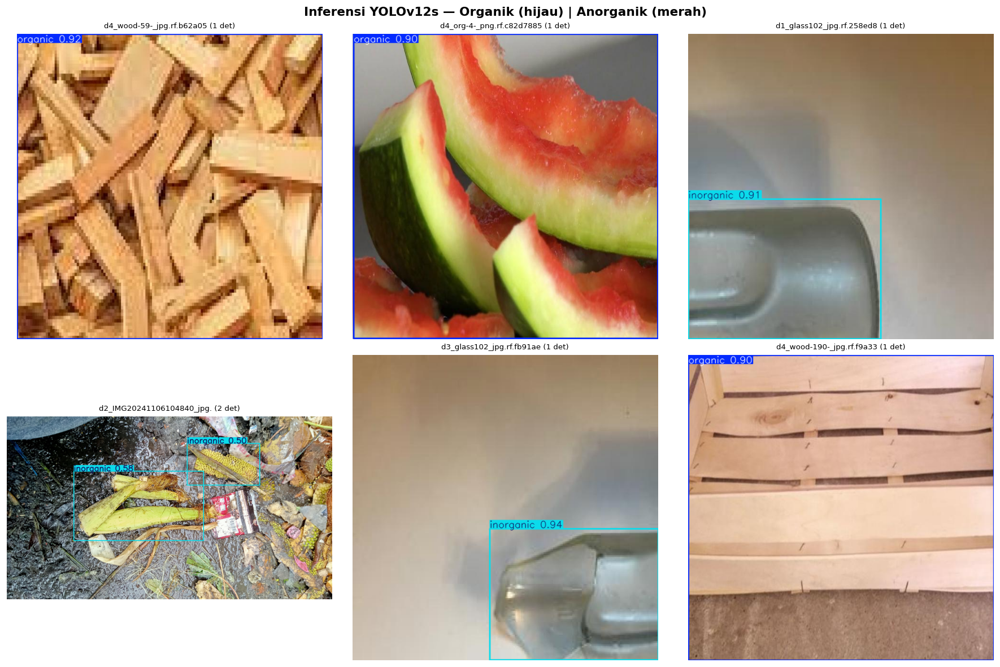

Hasil inferensi disimpan ke: /content/drive/MyDrive/YOLOv12_Sampah/results/inferensi_sample.png


In [ ]:
TRAIN_NAME = 'yolov12s_sampah_v1'
BEST_PT    = f'{RESULTS_PATH}/{TRAIN_NAME}/weights/best.pt'

test_img_dir = Path(SAMPLED_DATASET) / 'test' / 'images'
test_images  = list(test_img_dir.iterdir())[:6]

if not os.path.exists(BEST_PT):
    print('best.pt tidak ditemukan. Jalankan training terlebih dahulu.')
else:
    inf_model = YOLO(BEST_PT)
    CLASS_COLORS_BGR = {0: (0, 255, 0), 1: (0, 0, 255)}
    CLASS_NAMES_INF  = ['organic', 'inorganic']

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle('Inferensi YOLOv12s — Organik (hijau) | Anorganik (merah)', fontsize=13, fontweight='bold')

    for ax, img_path in zip(axes.flatten(), test_images):
        results = inf_model.predict(str(img_path), conf=0.25, iou=0.6, verbose=False)
        result  = results[0]
        img_bgr = result.plot()
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        ax.imshow(img_rgb)
        n_det = len(result.boxes) if result.boxes else 0
        ax.set_title(f'{img_path.name[:25]} ({n_det} det)', fontsize=8)
        ax.axis('off')

    plt.tight_layout()
    save_path = f'{RESULTS_PATH}/inferensi_sample.png'
    plt.savefig(save_path, dpi=100, bbox_inches='tight')
    plt.show()
    print(f'Hasil inferensi disimpan ke: {save_path}')

### 5.3 Grafik Training YOLOv12s

  Disimpan: /content/drive/MyDrive/YOLOv12_Sampah/results/visualisasi/B1_loss_curve.png


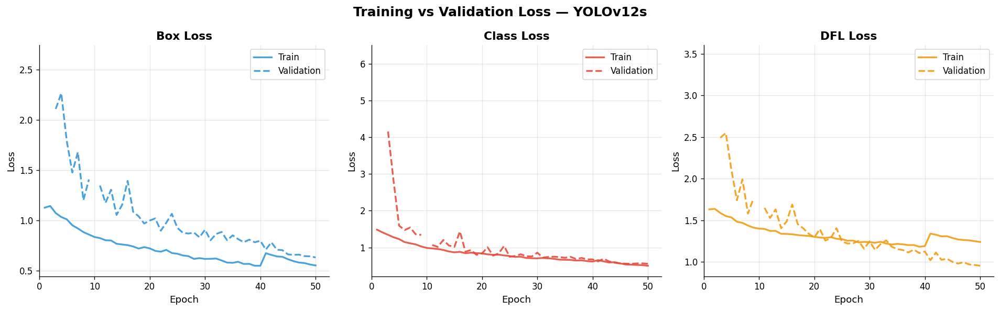

In [ ]:
# Training and Validation Loss -> apakah model konvergen baik
csv_path = f'{RESULTS_PATH}/{RUN_YOLOV12S}/results.csv'

if not os.path.exists(csv_path):
    print(f'File tidak ditemukan: {csv_path}')
else:
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    train_cols = ['train/box_loss','train/cls_loss','train/dfl_loss']
    val_cols   = ['val/box_loss',  'val/cls_loss',  'val/dfl_loss']
    labels     = ['Box Loss', 'Class Loss', 'DFL Loss']
    colors     = ['#3498db','#e74c3c','#f39c12']

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle('Training vs Validation Loss — YOLOv12s', fontsize=15, fontweight='bold')

    for ax, tc, vc, lbl, col in zip(axes, train_cols, val_cols, labels, colors):
        epochs = df['epoch']
        if tc in df.columns:
            ax.plot(epochs, df[tc], color=col, linewidth=2, label='Train', alpha=0.9)
        if vc in df.columns:
            ax.plot(epochs, df[vc], color=col, linewidth=2, linestyle='--', label='Validation', alpha=0.9)
        ax.set_title(lbl, fontweight='bold')
        ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
        ax.legend(); ax.set_xlim(left=0)

    plt.tight_layout()
    save_fig(fig, 'B1_loss_curve.png')

  Disimpan: /content/drive/MyDrive/YOLOv12_Sampah/results/visualisasi/B2_mAP_curve.png


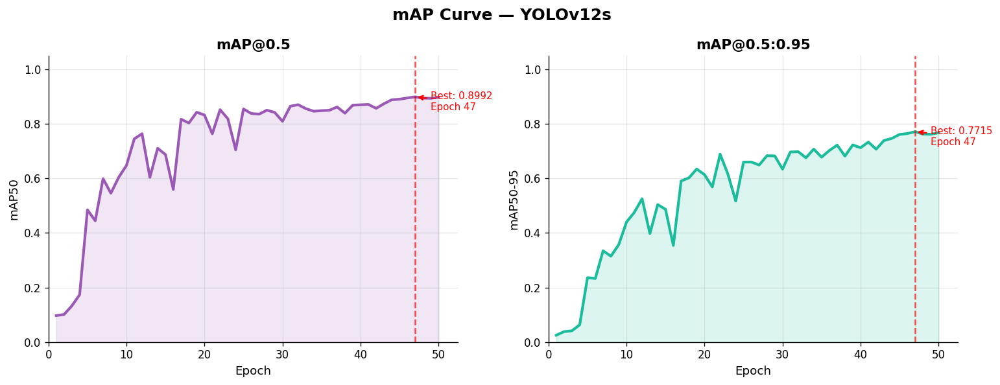

In [ ]:
if not os.path.exists(csv_path):
    print(f'File tidak ditemukan: {csv_path}')
else:
    df = pd.read_csv(csv_path); df.columns = df.columns.str.strip()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle('mAP Curve — YOLOv12s', fontsize=15, fontweight='bold')

    # mAP50
    ax = axes[0]
    if 'metrics/mAP50(B)' in df.columns:
        best_epoch = df['metrics/mAP50(B)'].idxmax()
        best_val   = df['metrics/mAP50(B)'].max()
        ax.plot(df['epoch'], df['metrics/mAP50(B)'], color='#9b59b6', linewidth=2.5)
        ax.fill_between(df['epoch'], df['metrics/mAP50(B)'], alpha=0.15, color='#9b59b6')
        ax.axvline(df['epoch'][best_epoch], color='red', linestyle='--', alpha=0.7)
        ax.annotate(f'Best: {best_val:.4f}\nEpoch {df["epoch"][best_epoch]:.0f}',
                    xy=(df['epoch'][best_epoch], best_val),
                    xytext=(df['epoch'][best_epoch]+2, best_val-0.05),
                    fontsize=9, color='red',
                    arrowprops=dict(arrowstyle='->', color='red', lw=1.5))
    ax.set_title('mAP@0.5', fontweight='bold')
    ax.set_xlabel('Epoch'); ax.set_ylabel('mAP50')
    ax.set_ylim(0, 1.05); ax.set_xlim(left=0)

    # mAP50-95
    ax2 = axes[1]
    if 'metrics/mAP50-95(B)' in df.columns:
        best_epoch2 = df['metrics/mAP50-95(B)'].idxmax()
        best_val2   = df['metrics/mAP50-95(B)'].max()
        ax2.plot(df['epoch'], df['metrics/mAP50-95(B)'], color='#1abc9c', linewidth=2.5)
        ax2.fill_between(df['epoch'], df['metrics/mAP50-95(B)'], alpha=0.15, color='#1abc9c')
        ax2.axvline(df['epoch'][best_epoch2], color='red', linestyle='--', alpha=0.7)
        ax2.annotate(f'Best: {best_val2:.4f}\nEpoch {df["epoch"][best_epoch2]:.0f}',
                    xy=(df['epoch'][best_epoch2], best_val2),
                    xytext=(df['epoch'][best_epoch2]+2, best_val2-0.05),
                    fontsize=9, color='red',
                    arrowprops=dict(arrowstyle='->', color='red', lw=1.5))
    ax2.set_title('mAP@0.5:0.95', fontweight='bold')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('mAP50-95')
    ax2.set_ylim(0, 1.05); ax2.set_xlim(left=0)

    plt.tight_layout()
    save_fig(fig, 'B2_mAP_curve.png')

  Disimpan: /content/drive/MyDrive/YOLOv12_Sampah/results/visualisasi/B3_precision_recall_curve.png


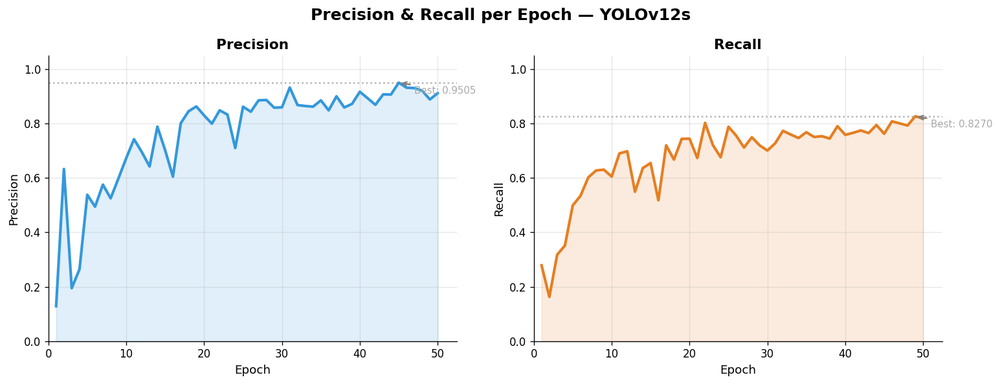

In [ ]:
# Precission and Recall Curve -> Curva per-epoch selama training
if not os.path.exists(csv_path):
    print(f'File tidak ditemukan: {csv_path}')
else:
    df = pd.read_csv(csv_path); df.columns = df.columns.str.strip()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle('Precision & Recall per Epoch — YOLOv12s', fontsize=15, fontweight='bold')

    for ax, col, label, color in [
        (axes[0], 'metrics/precision(B)', 'Precision', '#3498db'),
        (axes[1], 'metrics/recall(B)',    'Recall',    '#e67e22')
    ]:
        if col in df.columns:
            best_idx = df[col].idxmax()
            best_v   = df[col].max()
            ax.plot(df['epoch'], df[col], color=color, linewidth=2.5)
            ax.fill_between(df['epoch'], df[col], alpha=0.15, color=color)
            ax.axhline(best_v, color='gray', linestyle=':', alpha=0.6)
            ax.annotate(f'Best: {best_v:.4f}',
                        xy=(df['epoch'][best_idx], best_v),
                        xytext=(df['epoch'][best_idx]+2, best_v-0.04),
                        fontsize=9, color='darkgray',
                        arrowprops=dict(arrowstyle='->', color='gray', lw=1.5))
        ax.set_title(label, fontweight='bold')
        ax.set_xlabel('Epoch'); ax.set_ylabel(label)
        ax.set_ylim(0, 1.05); ax.set_xlim(left=0)

    plt.tight_layout()
    save_fig(fig, 'B3_precision_recall_curve.png')

### 5.4 Evaluasi & Confusion Matrix

Confusion matrix diambil dari hasil evaluasi.
  Disimpan: /content/drive/MyDrive/YOLOv12_Sampah/results/visualisasi/C1_confusion_matrix.png


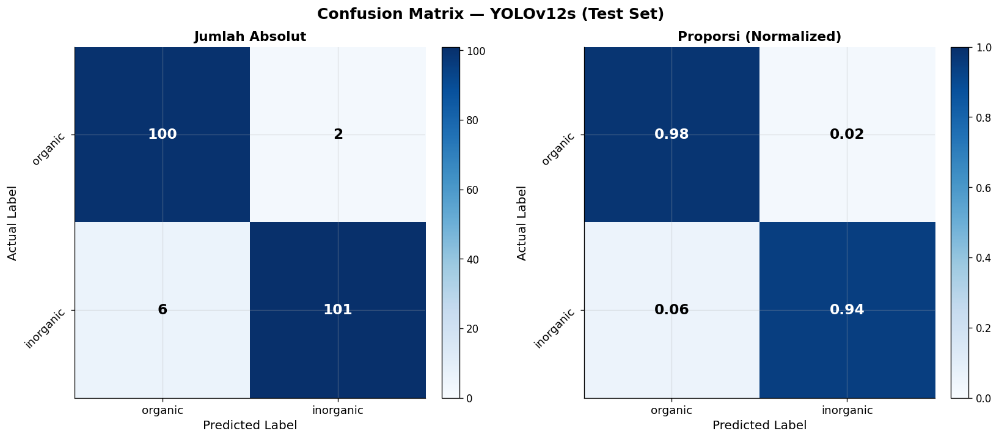

In [ ]:
try:
    cm_array = metrics.confusion_matrix.matrix
    print('Confusion matrix diambil dari hasil evaluasi.')
except:
    print('    Masukkan nilai confusion matrix secara manual di bawah:')
    print('    (Lihat output Cell 5.1 atau file confusion_matrix.csv)')
    cm_array = np.array([
        [180, 20],
        [15,  456],
    ])

n_classes = len(CLASS_NAMES)
cm = cm_array[:n_classes, :n_classes].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Confusion Matrix — YOLOv12s (Test Set)', fontsize=15, fontweight='bold')

for ax, normalize, title in [
    (axes[0], False, 'Jumlah Absolut'),
    (axes[1], True,  'Proporsi (Normalized)')
]:
    data = cm / cm.sum(axis=1, keepdims=True) if normalize else cm
    fmt  = '.2f' if normalize else '.0f'
    cmap = plt.cm.Blues
    im = ax.imshow(data, interpolation='nearest', cmap=cmap, vmin=0, vmax=1 if normalize else None)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    thresh = data.max() / 2
    for i in range(n_classes):
        for j in range(n_classes):
            val = f'{data[i,j]:{fmt}}'
            ax.text(j, i, val, ha='center', va='center', fontsize=14, fontweight='bold',
                    color='white' if data[i,j] > thresh else 'black')
    ax.set_xticks(range(n_classes)); ax.set_xticklabels(CLASS_NAMES, fontsize=11)
    ax.set_yticks(range(n_classes)); ax.set_yticklabels(CLASS_NAMES, fontsize=11, rotation=45)
    ax.set_xlabel('Predicted Label', fontsize=12); ax.set_ylabel('Actual Label', fontsize=12)
    ax.set_title(title, fontweight='bold')

plt.tight_layout()
save_fig(fig, 'C1_confusion_matrix.png')

  Disimpan: /content/drive/MyDrive/YOLOv12_Sampah/results/visualisasi/E1_f1_curve.png


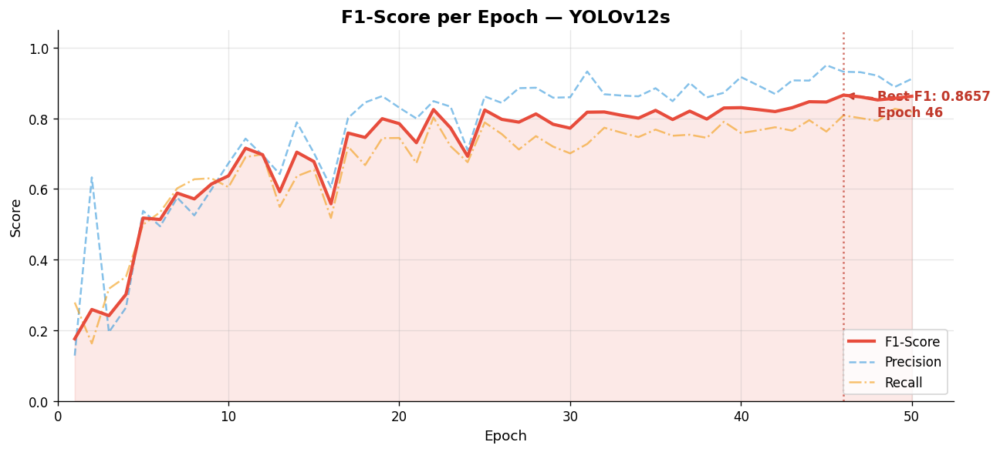

In [ ]:
#  F1-Score Curve per Epoch
# F1 = 2 * (Precision * Recall) / (Precision + Recall)
# Menunjukkan keseimbangan antara precision dan recall sepanjang training.

if not os.path.exists(csv_path):
    print(f'File tidak ditemukan: {csv_path}')
else:
    df = pd.read_csv(csv_path); df.columns = df.columns.str.strip()

    if 'metrics/precision(B)' in df.columns and 'metrics/recall(B)' in df.columns:
        P  = df['metrics/precision(B)']
        R  = df['metrics/recall(B)']
        F1 = 2 * P * R / (P + R + 1e-9)

        fig, ax = plt.subplots(figsize=(11, 5))
        ax.plot(df['epoch'], F1, color='#e74c3c', linewidth=2.5, label='F1-Score', zorder=5)
        ax.fill_between(df['epoch'], F1, alpha=0.12, color='#e74c3c')

        # Overlay precision & recall tipis
        ax.plot(df['epoch'], P, color='#3498db', linewidth=1.5, linestyle='--',
                alpha=0.6, label='Precision')
        ax.plot(df['epoch'], R, color='#f39c12', linewidth=1.5, linestyle='-.',
                alpha=0.6, label='Recall')

        best_idx = F1.idxmax()
        ax.axvline(df['epoch'][best_idx], color='#c0392b', linestyle=':', alpha=0.7)
        ax.annotate(f'Best F1: {F1[best_idx]:.4f}\nEpoch {df["epoch"][best_idx]:.0f}',
                    xy=(df['epoch'][best_idx], F1[best_idx]),
                    xytext=(df['epoch'][best_idx] + 2, F1[best_idx] - 0.06),
                    fontsize=10, color='#c0392b', fontweight='bold',
                    arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.8))

        ax.set_title('F1-Score per Epoch — YOLOv12s', fontsize=14, fontweight='bold')
        ax.set_xlabel('Epoch'); ax.set_ylabel('Score')
        ax.set_ylim(0, 1.05); ax.set_xlim(left=0)
        ax.legend(loc='lower right', fontsize=10)
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        save_fig(fig, 'E1_f1_curve.png')
    else:
        print('Kolom precision/recall tidak ditemukan di results.csv')


  Disimpan: /content/drive/MyDrive/YOLOv12_Sampah/results/visualisasi/E4_stacked_loss.png


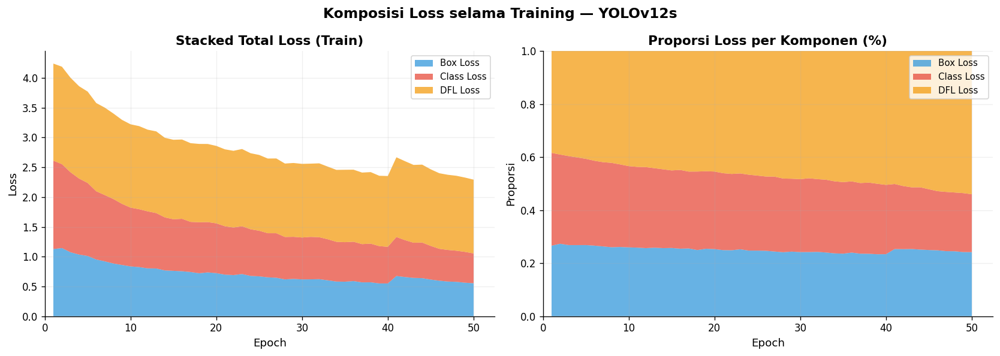

In [ ]:
if not os.path.exists(csv_path):
    print(f'File tidak ditemukan: {csv_path}')
else:
    df = pd.read_csv(csv_path); df.columns = df.columns.str.strip()

    loss_cols  = ['train/box_loss', 'train/cls_loss', 'train/dfl_loss']
    loss_names = ['Box Loss', 'Class Loss', 'DFL Loss']
    loss_colors= ['#3498db', '#e74c3c', '#f39c12']

    if all(c in df.columns for c in loss_cols):
        EP   = df['epoch'].values
        data = [df[c].values for c in loss_cols]

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle('Komposisi Loss selama Training — YOLOv12s',
                     fontsize=14, fontweight='bold')

        # Stacked area
        axes[0].stackplot(EP, data, labels=loss_names, colors=loss_colors, alpha=0.75)
        axes[0].set_title('Stacked Total Loss (Train)', fontweight='bold')
        axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
        axes[0].legend(loc='upper right', fontsize=9); axes[0].set_xlim(left=0)
        axes[0].grid(True, alpha=0.2)

        # Normalized stacked (proporsi per loss)
        total = np.array(data).sum(axis=0)
        norm  = [d / (total + 1e-9) for d in data]
        axes[1].stackplot(EP, norm, labels=loss_names, colors=loss_colors, alpha=0.75)
        axes[1].set_title('Proporsi Loss per Komponen (%)', fontweight='bold')
        axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Proporsi')
        axes[1].set_ylim(0, 1)
        axes[1].legend(loc='upper right', fontsize=9); axes[1].set_xlim(left=0)
        axes[1].grid(True, alpha=0.2)

        plt.tight_layout()
        save_fig(fig, 'E4_stacked_loss.png')


  Disimpan: /content/drive/MyDrive/YOLOv12_Sampah/results/visualisasi/E5_metrics_heatmap.png


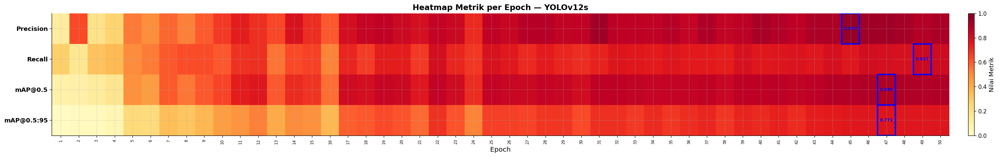

In [ ]:
# Visualisasi perkembangan performa training dari epoch ke epoch.
if not os.path.exists(csv_path):
    print(f'File tidak ditemukan: {csv_path}')
else:
    df = pd.read_csv(csv_path); df.columns = df.columns.str.strip()

    metric_cols = {
        'Precision'  : 'metrics/precision(B)',
        'Recall'     : 'metrics/recall(B)',
        'mAP@0.5'    : 'metrics/mAP50(B)',
        'mAP@0.5:95' : 'metrics/mAP50-95(B)',
    }
    available = {k: v for k, v in metric_cols.items() if v in df.columns}

    if available:
        heat_data = np.array([df[v].values for v in available.values()])
        epochs    = df['epoch'].values

        fig, ax = plt.subplots(figsize=(max(12, len(epochs)//2), 4))
        im = ax.imshow(heat_data, aspect='auto', cmap='YlOrRd',
                       vmin=0, vmax=1, interpolation='nearest')
        plt.colorbar(im, ax=ax, fraction=0.02, pad=0.02, label='Nilai Metrik')

        ax.set_yticks(range(len(available)))
        ax.set_yticklabels(list(available.keys()), fontsize=11, fontweight='bold')
        ax.set_xticks(range(len(epochs)))
        ax.set_xticklabels([str(int(e)) for e in epochs],
                           rotation=90, fontsize=7)
        ax.set_xlabel('Epoch', fontsize=12)
        ax.set_title('Heatmap Metrik per Epoch — YOLOv12s',
                     fontsize=14, fontweight='bold')

        for row_i, (name, col) in enumerate(available.items()):
            best_col = df[col].idxmax()
            ax.add_patch(plt.Rectangle((best_col - 0.5, row_i - 0.5), 1, 1,
                         fill=False, edgecolor='blue', linewidth=2.5))
            ax.text(best_col, row_i, f'{df[col].iloc[best_col]:.3f}',
                    ha='center', va='center', fontsize=7.5,
                    fontweight='bold', color='blue')

        plt.tight_layout()
        save_fig(fig, 'E5_metrics_heatmap.png')


## PART 6 — Inferensi Gambar dari Internet (Upload & Deteksi)


### 6.1 Upload & Deteksi Gambar dari Internet

Cell ini memungkinkan Anda untuk:
1. **Memasukkan URL gambar** dari internet (misal: foto sampah dari Google Images)
2. Model secara otomatis **mendeteksi** dan **mengklasifikasi** sampah
3. Hasil ditampilkan dengan **bounding box berlabel** Organik / Anorganik

> **Cara pakai:**
> - Jalankan cell di bawah
> - Ganti `IMAGE_URLS` dengan URL gambar yang Anda inginkan
> - Bisa memasukkan 1 hingga beberapa URL sekaligus

[OK] Model dimuat: /content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/weights/best.pt

--- Mengunduh 5 gambar dari internet ---
  [OK] Gambar 1: https://th.bing.com/th/id/OIP.Jw38K7gZsNgqZ_1Gsoj0VwHaE8?w=285&h=190&c...
  [OK] Gambar 2: https://api.content.travisperkins.co.uk/site/binaries/content/gallery/...
  [OK] Gambar 3: https://asset.mediaindonesia.com/news/2025/07/24/1753326849_158ede3ccc...
  [OK] Gambar 4: https://tse2.mm.bing.net/th/id/OIP.V1sQpkbPWn12XQEzMBxPUwHaE8?w=612&h=...
  [OK] Gambar 5: https://images.openai.com/static-rsc-4/WuBJDC_hZmBiKZFsh4yHF2V5krP-muR...

Total berhasil diunduh: 5 gambar


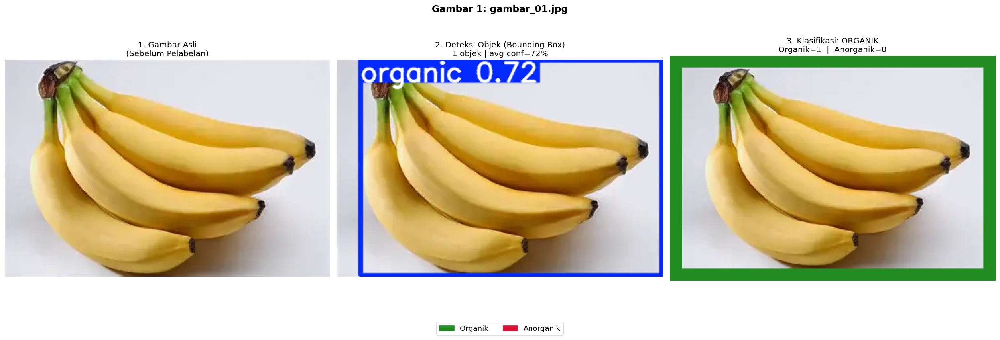

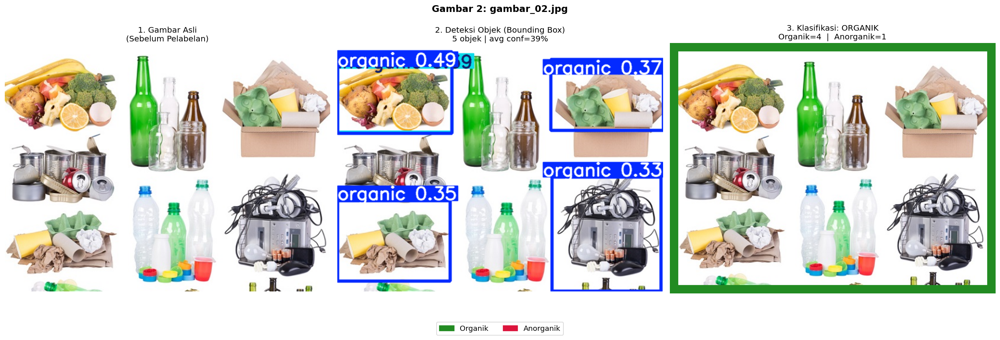

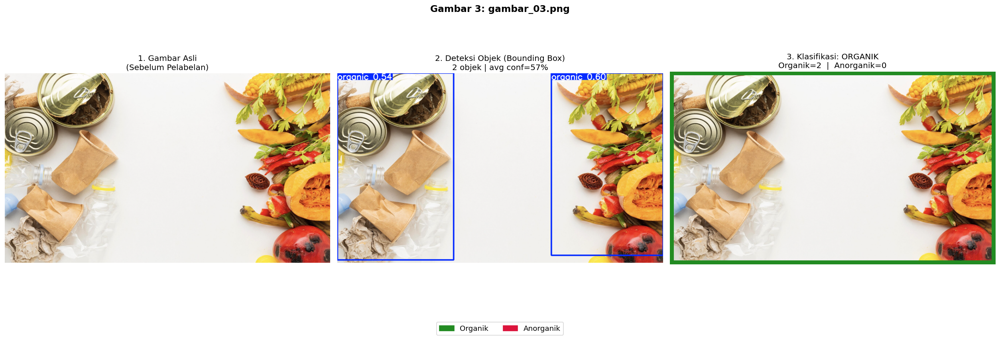

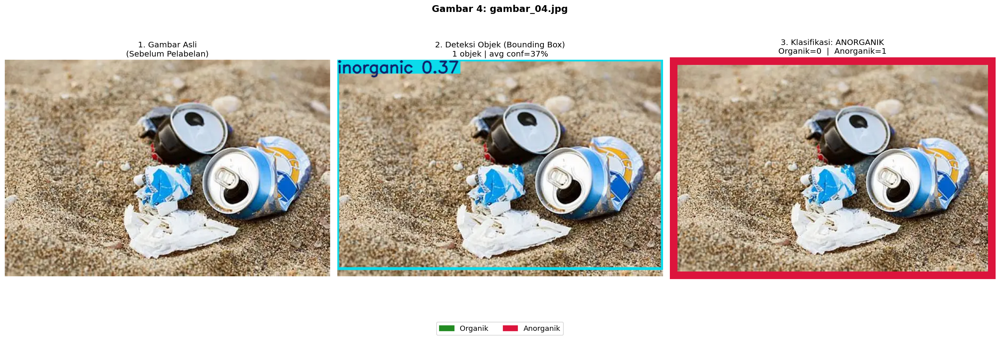

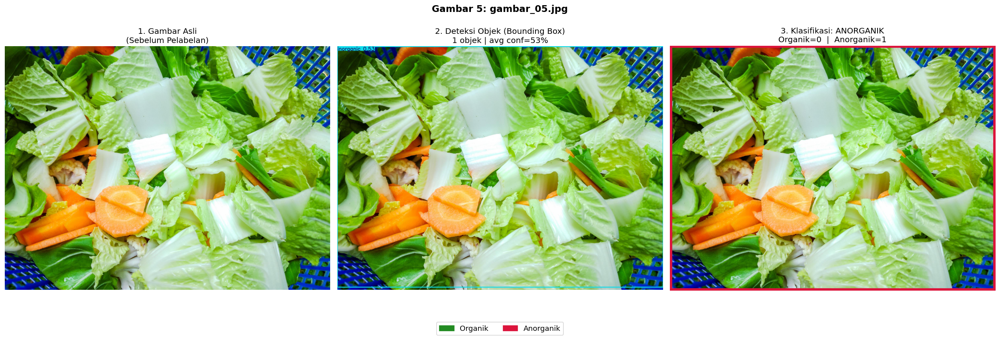


  RINGKASAN HASIL DETEKSI & KLASIFIKASI
No   File                         Total  Organik  Anorganik   Conf  Klasifikasi
----------------------------------------------------------------------
1    gambar_01.jpg                    1        1          0   72%      ORGANIK
2    gambar_02.jpg                    5        4          1   39%      ORGANIK
3    gambar_03.png                    2        2          0   57%      ORGANIK
4    gambar_04.jpg                    1        0          1   37%    ANORGANIK
5    gambar_05.jpg                    1        0          1   53%    ANORGANIK
Gambar hasil disimpan di: /content/drive/MyDrive/YOLOv12_Sampah/results/visualisasi/deteksi_klasifikasi_gambar_XX.png


In [ ]:
# ================================================================
# PART 6.2 — Deteksi & Klasifikasi Gambar dari URL
# Output per gambar: (1) Asli  (2) Deteksi/Bounding Box  (3) Klasifikasi Organik/Anorganik
# ================================================================

IMAGE_URLS = [
    'https://th.bing.com/th/id/OIP.Jw38K7gZsNgqZ_1Gsoj0VwHaE8?w=285&h=190&c=7&r=0&o=7&dpr=1.3&pid=1.7&rm=3',
    'https://api.content.travisperkins.co.uk/site/binaries/content/gallery/recycle-at-home-hero-v2.jpg',
    'https://asset.mediaindonesia.com/news/2025/07/24/1753326849_158ede3ccc9be3adb206.png',
    'https://tse2.mm.bing.net/th/id/OIP.V1sQpkbPWn12XQEzMBxPUwHaE8?w=612&h=408&rs=1&pid=ImgDetMain&o=7&rm=3',
    'https://images.openai.com/static-rsc-4/WuBJDC_hZmBiKZFsh4yHF2V5krP-muRjf6pUMCnVan7d_-at4Vl6IfU5JMZUFwuDg2EsbwO-n2hS1ddUyIrLgzmEApZ-ZpdUXi_xRBIOQr_984xi-tQibDyBDfr4dlDm4aIVolbMEhfAWk5SbDJFtvgyzY--2Jndv9euVUphfaND-MLozAqjm_LJ3-FR_USq?purpose=fullsize'

]

import urllib.request, os, cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from PIL import Image as PILImage
from ultralytics import YOLO

TRAIN_NAME      = 'yolov12s_sampah_v1'
CLASS_NAMES_INF = ['Organik', 'Anorganik']
CONF_THRESHOLD  = 0.25

# Warna untuk klasifikasi: Organik = hijau, Anorganik = merah
CLASS_COLORS = {
    'Organik':   (34, 139, 34),    # hijau
    'Anorganik': (220, 20, 60),    # merah
}

# ---- Cari best.pt ----
BEST_PT_CANDIDATES = [
    f'{RESULTS_PATH}/{TRAIN_NAME}/weights/best.pt',
    f'{WEIGHTS_PATH}/best.pt',
]
BEST_PT = None
for _p in BEST_PT_CANDIDATES:
    if os.path.exists(_p):
        BEST_PT = _p
        break

if BEST_PT is None:
    print('[ERROR] best.pt tidak ditemukan di lokasi berikut:')
    for _p in BEST_PT_CANDIDATES:
        print(f'  - {_p}')
    print()
    print('Pastikan training sudah selesai (PART 4) dan best.pt ada di salah satu lokasi di atas.')
else:
    print(f'[OK] Model dimuat: {BEST_PT}')
    inf_model = YOLO(BEST_PT)

    # ---- Download gambar dari URL ----
    download_dir = f'{DRIVE_PATH}/internet-image'
    os.makedirs(download_dir, exist_ok=True)
    downloaded_paths = []
    headers = {'User-Agent': 'Mozilla/5.0'}

    print(f'\n--- Mengunduh {len(IMAGE_URLS)} gambar dari internet ---')
    for i, url in enumerate(IMAGE_URLS):
        ext = url.split('?')[0].rsplit('.', 1)[-1].lower()
        if ext not in ['jpg', 'jpeg', 'png', 'webp', 'bmp']:
            ext = 'jpg'
        save_path = f'{download_dir}/gambar_{i+1:02d}.{ext}'
        try:
            req = urllib.request.Request(url, headers=headers)
            with urllib.request.urlopen(req, timeout=15) as resp, \
                 open(save_path, 'wb') as out:
                out.write(resp.read())
            downloaded_paths.append(save_path)
            print(f'  [OK] Gambar {i+1}: {url[:70]}...')
        except Exception as e:
            print(f'  [FAIL] Gagal download gambar {i+1}: {e}')

    print(f'\nTotal berhasil diunduh: {len(downloaded_paths)} gambar')

    all_results_summary = []

    if downloaded_paths:
        for idx, img_path in enumerate(downloaded_paths):

            # ---- Baca gambar asli ----
            img_original_bgr = cv2.imread(img_path)
            img_original_rgb = cv2.cvtColor(img_original_bgr, cv2.COLOR_BGR2RGB)

            # ---- Jalankan deteksi + klasifikasi ----
            results = inf_model.predict(
                img_path,
                conf=CONF_THRESHOLD,
                iou=0.45,
                max_det=100,
                agnostic_nms=False,
                verbose=False
            )
            result = results[0]

            # ---- Panel 2: Gambar dengan bounding box + label (Deteksi) ----
            img_detect_bgr = result.plot(
                conf=True,
                labels=True,
                boxes=True,
                line_width=3,
                font_size=14
            )
            img_detect_rgb = cv2.cvtColor(img_detect_bgr, cv2.COLOR_BGR2RGB)

            # ---- Hitung ringkasan klasifikasi ----
            det_summary = {'Organik': 0, 'Anorganik': 0}
            conf_list   = []
            if result.boxes is not None and len(result.boxes) > 0:
                for box in result.boxes:
                    cid  = int(box.cls.item())
                    conf = float(box.conf.item())
                    name = CLASS_NAMES_INF[cid] if cid < len(CLASS_NAMES_INF) else f'cls{cid}'
                    det_summary[name] = det_summary.get(name, 0) + 1
                    conf_list.append(conf)

            n_total     = sum(det_summary.values())
            avg_conf    = np.mean(conf_list) if conf_list else 0
            org_count   = det_summary.get('Organik', 0)
            inorg_count = det_summary.get('Anorganik', 0)

            # ---- Tentukan kelas dominan untuk Panel 3 (Klasifikasi) ----
            if n_total == 0:
                dominant_class = None
                border_color   = (128, 128, 128)  # abu-abu jika tidak terdeteksi
                klas_label     = 'Tidak terdeteksi'
            elif org_count >= inorg_count:
                dominant_class = 'Organik'
                border_color   = CLASS_COLORS['Organik']
                klas_label     = 'ORGANIK'
            else:
                dominant_class = 'Anorganik'
                border_color   = CLASS_COLORS['Anorganik']
                klas_label     = 'ANORGANIK'

            # ---- Panel 3: Gambar dengan border warna sesuai klasifikasi ----
            border_size = 15
            img_classify_rgb = cv2.copyMakeBorder(
                img_original_rgb, border_size, border_size, border_size, border_size,
                cv2.BORDER_CONSTANT, value=border_color
            )

            # ---- Plot 3 panel sejajar ----
            fig, axes = plt.subplots(1, 3, figsize=(21, 7))
            fig.suptitle(f'Gambar {idx+1}: {os.path.basename(img_path)}',
                         fontsize=14, fontweight='bold')

            axes[0].imshow(img_original_rgb)
            axes[0].set_title('1. Gambar Asli\n(Sebelum Pelabelan)', fontsize=12)
            axes[0].axis('off')

            if n_total == 0:
                title2 = '2. Deteksi Objek (Bounding Box)\nTidak ada objek terdeteksi'
            else:
                title2 = (f'2. Deteksi Objek (Bounding Box)\n'
                          f'{n_total} objek | avg conf={avg_conf:.0%}')
            axes[1].imshow(img_detect_rgb)
            axes[1].set_title(title2, fontsize=12)
            axes[1].axis('off')

            title3 = (f'3. Klasifikasi: {klas_label}\n'
                      f'Organik={org_count}  |  Anorganik={inorg_count}')
            axes[2].imshow(img_classify_rgb)
            axes[2].set_title(title3, fontsize=12)
            axes[2].axis('off')

            # Legenda warna klasifikasi
            legend_patches = [
                mpatches.Patch(color=np.array(CLASS_COLORS['Organik'])/255, label='Organik'),
                mpatches.Patch(color=np.array(CLASS_COLORS['Anorganik'])/255, label='Anorganik'),
            ]
            fig.legend(handles=legend_patches, loc='lower center', ncol=2,
                       bbox_to_anchor=(0.5, -0.02), fontsize=11)

            plt.tight_layout(rect=[0, 0.03, 1, 1])
            save_out = f'{VIZ_PATH}/deteksi_klasifikasi_gambar_{idx+1:02d}.png'
            plt.savefig(save_out, dpi=130, bbox_inches='tight', facecolor='white')
            plt.show()

            all_results_summary.append({
                'file': os.path.basename(img_path),
                'total': n_total,
                'organik': org_count,
                'anorganik': inorg_count,
                'avg_conf': avg_conf,
                'klasifikasi': klas_label
            })

        # ---- Ringkasan akhir semua gambar ----
        print('\n' + '='*70)
        print('  RINGKASAN HASIL DETEKSI & KLASIFIKASI')
        print('='*70)
        print(f'{"No":<4} {"File":<28} {"Total":>5} {"Organik":>8} {"Anorganik":>10} {"Conf":>6} {"Klasifikasi":>12}')
        print('-'*70)
        for i, r in enumerate(all_results_summary):
            print(f'{i+1:<4} {r["file"]:<28} {r["total"]:>5} '
                  f'{r["organik"]:>8} {r["anorganik"]:>10} {r["avg_conf"]:>5.0%} {r["klasifikasi"]:>12}')
        print('='*70)
        print(f'Gambar hasil disimpan di: {VIZ_PATH}/deteksi_klasifikasi_gambar_XX.png')
    else:
        print('[ERROR] Tidak ada gambar yang berhasil diunduh. Cek URL Anda.')


[OK] Model dimuat: /content/drive/MyDrive/YOLOv12_Sampah/results/yolov12s_sampah_v1/weights/best.pt

--- Mengunduh 2 gambar dari internet ---
  [OK] Gambar 1: https://th.bing.com/th/id/OIP.Jw38K7gZsNgqZ_1Gsoj0VwHaE8?w=285&h=190&c...
  [OK] Gambar 2: https://api.content.travisperkins.co.uk/site/binaries/content/gallery/...

Total berhasil diunduh: 2 gambar


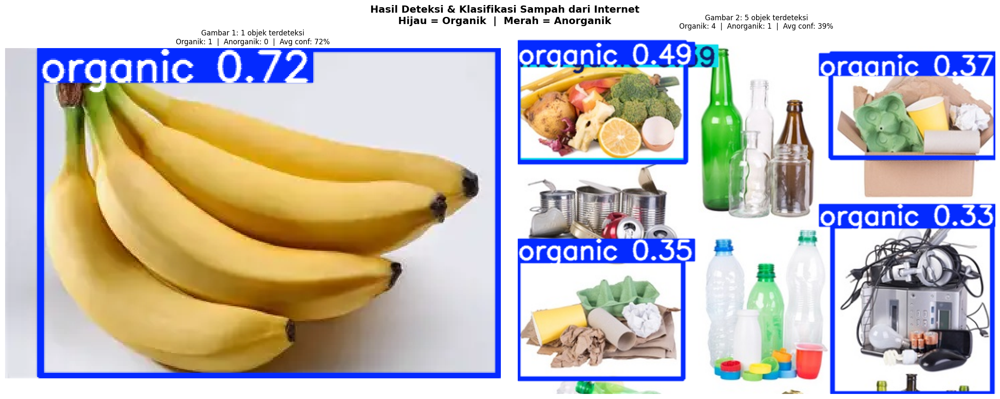


Hasil deteksi disimpan ke: /content/drive/MyDrive/YOLOv12_Sampah/results/visualisasi/deteksi_internet.png
Label: Hijau = ORGANIK | Merah = ANORGANIK
Confidence ditampilkan di setiap bounding box


In [ ]:
IMAGE_URLS = [
    'https://th.bing.com/th/id/OIP.Jw38K7gZsNgqZ_1Gsoj0VwHaE8?w=285&h=190&c=7&r=0&o=7&dpr=1.3&pid=1.7&rm=3',
    'https://api.content.travisperkins.co.uk/site/binaries/content/gallery/recycle-at-home-hero-v2.jpg'
]


import urllib.request, os, cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image as PILImage
from ultralytics import YOLO

TRAIN_NAME      = 'yolov12s_sampah_v1'
CLASS_NAMES_INF = ['Organik', 'Anorganik']
CONF_THRESHOLD  = 0.25


BEST_PT_CANDIDATES = [
    f'{RESULTS_PATH}/{TRAIN_NAME}/weights/best.pt',
    f'{WEIGHTS_PATH}/best.pt',
]

BEST_PT = None
for _p in BEST_PT_CANDIDATES:
    if os.path.exists(_p):
        BEST_PT = _p
        break

if BEST_PT is None:
    print('[ERROR] best.pt tidak ditemukan di lokasi berikut:')
    for _p in BEST_PT_CANDIDATES:
        print(f'  - {_p}')
    print()
    print('Pastikan training sudah selesai (PART 4) dan best.pt ada di salah satu lokasi di atas.')
    print('Jika training sudah selesai, jalankan cell backup best.pt di bawah terlebih dahulu.')
else:
    print(f'[OK] Model dimuat: {BEST_PT}')
    inf_model = YOLO(BEST_PT)

    download_dir = '{DRIVE_PATH}/internet-image'
    os.makedirs(download_dir, exist_ok=True)
    downloaded_paths = []
    headers = {'User-Agent': 'Mozilla/5.0'}

    print(f'\n--- Mengunduh {len(IMAGE_URLS)} gambar dari internet ---')
    for i, url in enumerate(IMAGE_URLS):
        ext = url.split('?')[0].rsplit('.', 1)[-1].lower()
        if ext not in ['jpg', 'jpeg', 'png', 'webp', 'bmp']:
            ext = 'jpg'
        save_path = f'{download_dir}/gambar_{i+1:02d}.{ext}'
        try:
            req = urllib.request.Request(url, headers=headers)
            with urllib.request.urlopen(req, timeout=15) as resp, \
                 open(save_path, 'wb') as out:
                out.write(resp.read())
            downloaded_paths.append(save_path)
            print(f'  [OK] Gambar {i+1}: {url[:70]}...')
        except Exception as e:
            print(f'  [FAIL] Gagal download gambar {i+1}: {e}')

    print(f'\nTotal berhasil diunduh: {len(downloaded_paths)} gambar')

    if downloaded_paths:
        n     = len(downloaded_paths)
        ncols = min(n, 2)
        nrows = (n + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols,
                                  figsize=(10 * ncols, 8 * nrows))
        if n == 1:
            axes = [[axes]]
        elif ncols == 1:
            axes = [[ax] for ax in axes]
        elif nrows == 1:
            axes = [axes]

        fig.suptitle('Hasil Deteksi & Klasifikasi Sampah dari Internet\n'
                     'Hijau = Organik  |  Merah = Anorganik',
                     fontsize=14, fontweight='bold')

        for idx, img_path in enumerate(downloaded_paths):
            r, c = divmod(idx, ncols)
            ax = axes[r][c]

            results = inf_model.predict(
                img_path,
                conf=CONF_THRESHOLD,
                iou=0.45,
                max_det=100,
                agnostic_nms=False,
                verbose=False
            )
            result = results[0]

            # Plot dengan YOLO built-in (bounding box + label + confidence)
            img_bgr = result.plot(
                conf=True,
                labels=True,
                boxes=True,
                line_width=3,
                font_size=14
            )
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            ax.imshow(img_rgb)

            # Hitung ringkasan deteksi
            det_summary = {'Organik': 0, 'Anorganik': 0}
            conf_list   = []
            if result.boxes is not None and len(result.boxes) > 0:
                for box in result.boxes:
                    cid  = int(box.cls.item())
                    conf = float(box.conf.item())
                    name = CLASS_NAMES_INF[cid] if cid < len(CLASS_NAMES_INF) else f'cls{cid}'
                    det_summary[name] = det_summary.get(name, 0) + 1
                    conf_list.append(conf)

            n_total     = sum(det_summary.values())
            avg_conf    = np.mean(conf_list) if conf_list else 0
            org_count   = det_summary.get('Organik', 0)
            inorg_count = det_summary.get('Anorganik', 0)

            if n_total == 0:
                title = (f'Gambar {idx+1}: Tidak ada objek terdeteksi\n'
                         f'(coba turunkan CONF_THRESHOLD atau periksa kualitas gambar)')
            else:
                title = (f'Gambar {idx+1}: {n_total} objek terdeteksi\n'
                         f'Organik: {org_count}  |  Anorganik: {inorg_count}  '
                         f'|  Avg conf: {avg_conf:.0%}')
            ax.set_title(title, fontsize=10)
            ax.axis('off')

        for idx in range(n, nrows * ncols):
            r, c = divmod(idx, ncols)
            axes[r][c].axis('off')

        plt.tight_layout()
        save_out = f'{VIZ_PATH}/deteksi_internet.png'
        plt.savefig(save_out, dpi=130, bbox_inches='tight', facecolor='white')
        plt.show()
        print(f'\nHasil deteksi disimpan ke: {save_out}')
        print('Label: Hijau = ORGANIK | Merah = ANORGANIK')
        print('Confidence ditampilkan di setiap bounding box')
    else:
        print('[ERROR] Tidak ada gambar yang berhasil diunduh. Cek URL Anda.')


### 6.2 Hasil Klasifikasi Sampah Organik dan Anorganik

In [ ]:
# ================================================================
# 6.2 UPLOAD FILE DARI KOMPUTER / GOOGLE DRIVE
# ================================================================
# Opsi A — Upload dari komputer lokal: jalankan cell ini,
#           klik tombol 'Choose Files', pilih gambar sampah Anda.
# Opsi B — Dari Google Drive: ubah USE_DRIVE = True dan
#           isi DRIVE_IMAGE_DIR dengan path folder di Drive.

USE_DRIVE       = False
DRIVE_IMAGE_DIR = '/content/drive/MyDrive/gambar_sampah_test/'

import os, cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

TRAIN_NAME      = 'yolov12s_sampah_v1'
CLASS_NAMES_INF = ['Organik', 'Anorganik']
CONF_THRESHOLD  = 0.25

# Cari best.pt
BEST_PT_CANDIDATES = [
    f'{RESULTS_PATH}/{TRAIN_NAME}/weights/best.pt',
    f'{WEIGHTS_PATH}/best.pt',
]
BEST_PT = None
for _p in BEST_PT_CANDIDATES:
    if os.path.exists(_p):
        BEST_PT = _p
        break

if BEST_PT is None:
    print('[ERROR] best.pt tidak ditemukan. Pastikan training sudah selesai.')
else:
    inf_model = YOLO(BEST_PT)
    print(f'[OK] Model siap: {BEST_PT}')

    # ---- Kumpulkan gambar ----
    image_paths = []

    if USE_DRIVE:
        exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
        for fn in os.listdir(DRIVE_IMAGE_DIR):
            if os.path.splitext(fn)[1].lower() in exts:
                image_paths.append(os.path.join(DRIVE_IMAGE_DIR, fn))
        print(f'Ditemukan {len(image_paths)} gambar di Drive: {DRIVE_IMAGE_DIR}')
    else:
        from google.colab import files
        print('Pilih gambar sampah dari komputer Anda (bisa multiple):')
        uploaded = files.upload()
        upload_dir = '/content/uploaded_images'
        os.makedirs(upload_dir, exist_ok=True)
        for fn, data in uploaded.items():
            dest = f'{upload_dir}/{fn}'
            with open(dest, 'wb') as f:
                f.write(data)
            image_paths.append(dest)
        print(f'Terupload: {len(image_paths)} gambar')

    # ---- Inferensi & Visualisasi ----
    if image_paths:
        n     = len(image_paths)
        ncols = min(n, 3)
        nrows = (n + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols,
                                  figsize=(9 * ncols, 7 * nrows))
        if n == 1:
            axes = [[axes]]
        elif ncols == 1:
            axes = [[ax] for ax in axes]
        elif nrows == 1:
            axes = [axes]

        fig.suptitle('Hasil Deteksi & Klasifikasi Sampah\n'
                     'Hijau = Organik  |  Merah = Anorganik',
                     fontsize=14, fontweight='bold')

        all_results_summary = []

        for idx, img_path in enumerate(image_paths):
            r, c = divmod(idx, ncols)
            ax   = axes[r][c]

            results = inf_model.predict(
                img_path,
                conf=CONF_THRESHOLD,
                iou=0.45,
                max_det=100,
                agnostic_nms=False,
                verbose=False
            )
            result = results[0]

            img_bgr = result.plot(conf=True, labels=True, boxes=True,
                                   line_width=3, font_size=14)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            ax.imshow(img_rgb)

            det_summary = {}
            conf_list   = []
            if result.boxes is not None and len(result.boxes) > 0:
                for box in result.boxes:
                    cid  = int(box.cls.item())
                    conf = float(box.conf.item())
                    name = CLASS_NAMES_INF[cid] if cid < len(CLASS_NAMES_INF) else f'cls{cid}'
                    det_summary[name] = det_summary.get(name, 0) + 1
                    conf_list.append(conf)

            n_total     = sum(det_summary.values())
            avg_conf    = np.mean(conf_list) if conf_list else 0
            fname       = os.path.basename(img_path)[:30]
            org_count   = det_summary.get('Organik', 0)
            inorg_count = det_summary.get('Anorganik', 0)

            if n_total == 0:
                title = f'{fname}\nTidak ada objek terdeteksi'
            else:
                title = (f'{fname}\n'
                         f'{n_total} objek: Organik={org_count}, Anorganik={inorg_count}'
                         f' | conf={avg_conf:.0%}')
            ax.set_title(title, fontsize=9)
            ax.axis('off')

            all_results_summary.append({
                'file': fname,
                'total': n_total,
                'organik': org_count,
                'anorganik': inorg_count,
                'avg_conf': avg_conf
            })

        for idx in range(n, nrows * ncols):
            r, c = divmod(idx, ncols)
            axes[r][c].axis('off')

        plt.tight_layout()
        save_out = f'{VIZ_PATH}/deteksi_upload.png'
        plt.savefig(save_out, dpi=130, bbox_inches='tight', facecolor='white')
        plt.show()

        print('\n' + '='*60)
        print('  RINGKASAN HASIL KLASIFIKASI')
        print('='*60)
        print(f'{"No":<4} {"File":<32} {"Total":>5} {"Organik":>8} {"Anorganik":>10} {"Conf":>6}')
        print('-'*60)
        for i, r in enumerate(all_results_summary):
            print(f'{i+1:<4} {r["file"]:<32} {r["total"]:>5} '
                  f'{r["organik"]:>8} {r["anorganik"]:>10} {r["avg_conf"]:>5.0%}')
        print('='*60)
        print(f'Hasil deteksi disimpan ke: {save_out}')
    else:
        print('[ERROR] Tidak ada gambar yang tersedia.')
